In [1]:
# Cell 1 — Environment check

import os
import sys
import platform

print("Python version:")
print(sys.version)

print("\nPlatform:")
print(platform.platform())

print("\nCPU cores:")
print(os.cpu_count())

print("\nOperating system:")
!cat /etc/os-release | grep PRETTY_NAME

print("\nGPU information:")
!nvidia-smi

Python version:
3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]

Platform:
Linux-6.6.122+-x86_64-with-glibc2.35

CPU cores:
8

Operating system:
PRETTY_NAME="Ubuntu 22.04.5 LTS"

GPU information:
Sat Oct 10 12:11:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             12W

In [2]:
# Cell 2 — Install and import required libraries

!pip install -q tensorflow_decision_forests==1.12.0
!pip install -q imbalanced-learn

import os
import time
import gc
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import tensorflow_decision_forests as tfdf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.utils.class_weight import (
    compute_class_weight
)

from sklearn.preprocessing import LabelEncoder

from imblearn.over_sampling import (
    SMOTE,
    ADASYN
)

from imblearn.ensemble import (
    BalancedRandomForestClassifier
)

print(
    "TensorFlow version:",
    tf.__version__
)

print(
    "TensorFlow Decision Forests version:",
    tfdf.__version__
)

import imblearn

print(
    "imbalanced-learn version:",
    imblearn.__version__
)

TensorFlow version: 2.19.0
TensorFlow Decision Forests version: 1.12.0
imbalanced-learn version: 0.14.1


In [3]:
# Cell 3 — Mount Google Drive

from google.colab import drive

drive.mount(
    "/content/drive"
)

print(
    "Google Drive mounted."
)

Mounted at /content/drive
Google Drive mounted.


In [4]:
# Cell 4 — Define project paths

PROJECT_DIR = (
    "/content/drive/MyDrive/MSc_Project"
)

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "CICIDS2017",
    "processed"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_I1_CIC"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "RF_I1_CIC"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

TRAIN_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_train.parquet"
)

VAL_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_validation.parquet"
)

TEST_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_test.parquet"
)

BEST_TUNING_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H3_CIC",
    "RF_best_tuned_configuration.csv"
)

RF_H2_METRICS_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H2_CIC",
    "RF_H2_CIC_metrics.csv"
)

RF_F1_DECISION_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_F1_CIC",
    "RF_F1_feature_refinement_decision.csv"
)

LABEL_COL = "Label"

print(
    "Results directory:",
    RESULTS_DIR
)

print(
    "Model directory:",
    MODEL_DIR
)

Results directory: /content/drive/MyDrive/MSc_Project/results/RF_I1_CIC
Model directory: /content/drive/MyDrive/MSc_Project/models/RF_I1_CIC


In [5]:
# Cell 5 — Verify frozen inputs

required_files = {
    "Training set":
        TRAIN_PATH,

    "Validation set":
        VAL_PATH,

    "Held-out test set":
        TEST_PATH,

    "Best tuned configuration":
        BEST_TUNING_PATH,

    "RF-H2 metrics":
        RF_H2_METRICS_PATH,

    "RF-F1 decision":
        RF_F1_DECISION_PATH
}

print(
    "Frozen input checks:\n"
)

all_inputs_exist = True

for name, path in required_files.items():

    exists = os.path.exists(
        path
    )

    print(
        f"{name}: {exists}"
    )

    if not exists:
        all_inputs_exist = False

if not all_inputs_exist:

    raise FileNotFoundError(
        "One or more required frozen inputs are missing."
    )

# --------------------------------------------------
# Load frozen RF configuration
# --------------------------------------------------

best_tuning_df = pd.read_csv(
    BEST_TUNING_PATH
)

display(
    best_tuning_df
)

BEST_TUNED_TREES = int(
    best_tuning_df.iloc[0][
        "Trees"
    ]
)

BEST_TUNED_MAX_DEPTH = int(
    best_tuning_df.iloc[0][
        "Max Depth"
    ]
)

BEST_TUNED_MIN_EXAMPLES = int(
    best_tuning_df.iloc[0][
        "Min Examples"
    ]
)

BEST_TUNED_RANDOM_SEED = int(
    best_tuning_df.iloc[0][
        "Random Seed"
    ]
)

# --------------------------------------------------
# Confirm RF-F1 was not selected
# --------------------------------------------------

rf_f1_decision_df = pd.read_csv(
    RF_F1_DECISION_PATH
)

display(
    rf_f1_decision_df
)

feature_selected = (
    str(
        rf_f1_decision_df.iloc[0][
            "Feature Refinement Selected"
        ]
    )
    .strip()
    .lower()
    == "true"
)

assert feature_selected is False

print(
    "\nConfiguration carried into imbalance stage:"
)

print(
    "Trees:",
    BEST_TUNED_TREES
)

print(
    "Max depth:",
    BEST_TUNED_MAX_DEPTH
)

print(
    "Min examples:",
    BEST_TUNED_MIN_EXAMPLES
)

print(
    "Random seed:",
    BEST_TUNED_RANDOM_SEED
)

print(
    "\nFeature refinement selected:",
    feature_selected
)

print(
    "\nImbalance stage will therefore use "
    "the original CIC feature space."
)

Frozen input checks:

Training set: True
Validation set: True
Held-out test set: True
Best tuned configuration: True
RF-H2 metrics: True
RF-F1 decision: True


,Selected Model,Trees,Max Depth,Min Examples,Random Seed,Selection Metric,Validation Macro F1
0,RF-H2-CIC,100,30,1,42,Validation Macro F1,0.881331


,Baseline Tuned Model,Feature-Refined Model,RF-H2 Validation Macro F1,RF-F1 Validation Macro F1,Absolute Delta,Relative Delta Percent,Feature Refinement Selected,Decision
0,RF-H2-CIC,RF-F1-CIC,0.881331,0.847499,-0.033832,-3.83877,False,RF-F1 not selected over RF-H2 because validati...



Configuration carried into imbalance stage:
Trees: 100
Max depth: 30
Min examples: 1
Random seed: 42

Feature refinement selected: False

Imbalance stage will therefore use the original CIC feature space.


In [6]:
# Cell 6 — Load frozen CIC-IDS2017 datasets

print(
    "Loading frozen CIC-IDS2017 datasets..."
)

train_df = pd.read_parquet(
    TRAIN_PATH
)

val_df = pd.read_parquet(
    VAL_PATH
)

test_df = pd.read_parquet(
    TEST_PATH
)

print(
    "\nDataset shapes:"
)

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

print(
    "\nMissing values:"
)

print(
    "Train:",
    int(
        train_df.isna()
        .sum()
        .sum()
    )
)

print(
    "Validation:",
    int(
        val_df.isna()
        .sum()
        .sum()
    )
)

print(
    "Test:",
    int(
        test_df.isna()
        .sum()
        .sum()
    )
)

Loading frozen CIC-IDS2017 datasets...

Dataset shapes:
Train: (1764554, 79)
Validation: (378119, 79)
Test: (378119, 79)

Missing values:
Train: 0
Validation: 0
Test: 0


In [7]:
# Cell 7 — Confirm frozen feature and class structure

CLASS_NAMES = [
    "BENIGN",
    "Bot",
    "DDoS",
    "DoS GoldenEye",
    "DoS Hulk",
    "DoS Slowhttptest",
    "DoS slowloris",
    "FTP-Patator",
    "Heartbleed",
    "Infiltration",
    "PortScan",
    "SSH-Patator",
    "Web Attack - Brute Force",
    "Web Attack - SQL Injection",
    "Web Attack - XSS"
]

FEATURE_COLS = [
    column
    for column in train_df.columns
    if column != LABEL_COL
]

print(
    "Input features:",
    len(
        FEATURE_COLS
    )
)

print(
    "Classes:",
    len(
        CLASS_NAMES
    )
)

assert len(
    FEATURE_COLS
) == 78

assert (
    list(
        train_df[
            FEATURE_COLS
        ].columns
    )
    ==
    list(
        val_df[
            FEATURE_COLS
        ].columns
    )
)

assert (
    list(
        train_df[
            FEATURE_COLS
        ].columns
    )
    ==
    list(
        test_df[
            FEATURE_COLS
        ].columns
    )
)

assert (
    set(
        train_df[
            LABEL_COL
        ].unique()
    )
    ==
    set(
        CLASS_NAMES
    )
)

print(
    "\nFeature and class integrity checks: PASSED"
)

print(
    "\nOriginal 78-feature space restored "
    "for imbalance experiments."
)

Input features: 78
Classes: 15

Feature and class integrity checks: PASSED

Original 78-feature space restored for imbalance experiments.


In [8]:
# Cell 8 — Analyse training class imbalance

train_class_counts = (
    train_df[
        LABEL_COL
    ]
    .value_counts()
    .reindex(
        CLASS_NAMES
    )
)

train_class_percentages = (
    train_class_counts
    / len(
        train_df
    )
) * 100

imbalance_summary_df = pd.DataFrame({
    "Class":
        CLASS_NAMES,

    "Training Count":
        train_class_counts.values,

    "Training Percentage":
        train_class_percentages.values
})

majority_count = int(
    train_class_counts.max()
)

minority_count = int(
    train_class_counts.min()
)

imbalance_ratio = (
    majority_count
    / minority_count
)

print(
    "Training class distribution:"
)

display(
    imbalance_summary_df
)

print(
    "\nMajority-class count:",
    majority_count
)

print(
    "Smallest-class count:",
    minority_count
)

print(
    "Majority/minority ratio:",
    round(
        imbalance_ratio,
        2
    ),
    ": 1"
)

# --------------------------------------------------
# Save evidence
# --------------------------------------------------

IMBALANCE_SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_training_class_distribution.csv"
)

imbalance_summary_df.to_csv(
    IMBALANCE_SUMMARY_PATH,
    index=False
)

print(
    "\nClass-distribution file saved:",
    os.path.exists(
        IMBALANCE_SUMMARY_PATH
    )
)

Training class distribution:


,Class,Training Count,Training Percentage
0,BENIGN,1466535,83.110803
1,Bot,1364,0.077300
2,DDoS,89610,5.078337
3,DoS GoldenEye,7200,0.408035
4,DoS Hulk,120992,6.856803
5,DoS Slowhttptest,3660,0.207418
6,DoS slowloris,3769,0.213595
7,FTP-Patator,4152,0.235300
8,Heartbleed,8,0.000453
9,Infiltration,25,0.001417



Majority-class count: 1466535
Smallest-class count: 8
Majority/minority ratio: 183316.88 : 1

Class-distribution file saved: True


In [9]:
# Cell 9 — Define and lock imbalance experiment design
# No training or resampling occurs in this cell.

print(
    "Defining imbalance experiment design..."
)

# --------------------------------------------------
# 1. Fixed design parameters
# --------------------------------------------------

IMBALANCE_RANDOM_SEED = 42

OVERSAMPLE_MULTIPLIER = 10
OVERSAMPLE_CAP = 10_000

BRF_UNDERSAMPLE_CAP = 10_000

PRIMARY_SELECTION_METRIC = (
    "Validation Macro F1"
)

# --------------------------------------------------
# 2. Standard balanced class weights
# --------------------------------------------------

class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.array(
        CLASS_NAMES
    ),
    y=train_df[
        LABEL_COL
    ]
)

CLASS_WEIGHT_MAP = {
    class_name: float(weight)
    for class_name, weight
    in zip(
        CLASS_NAMES,
        class_weight_values
    )
}

class_weight_df = pd.DataFrame({
    "Class":
        CLASS_NAMES,

    "Training Count": [
        int(
            train_class_counts[
                class_name
            ]
        )
        for class_name
        in CLASS_NAMES
    ],

    "Balanced Weight": [
        CLASS_WEIGHT_MAP[
            class_name
        ]
        for class_name
        in CLASS_NAMES
    ]
})

print(
    "\nBalanced class weights:"
)

display(
    class_weight_df
)

print(
    "Minimum class weight:",
    round(
        class_weight_df[
            "Balanced Weight"
        ].min(),
        6
    )
)

print(
    "Maximum class weight:",
    round(
        class_weight_df[
            "Balanced Weight"
        ].max(),
        6
    )
)

# --------------------------------------------------
# 3. Controlled SMOTE / ADASYN targets
# --------------------------------------------------

OVERSAMPLING_TARGETS = {}

oversampling_rows = []

for class_name in CLASS_NAMES:

    original_count = int(
        train_class_counts[
            class_name
        ]
    )

    if original_count < OVERSAMPLE_CAP:

        target_count = min(
            original_count
            * OVERSAMPLE_MULTIPLIER,
            OVERSAMPLE_CAP
        )

    else:

        target_count = original_count

    oversampling_rows.append({
        "Class":
            class_name,

        "Original Count":
            original_count,

        "Target Count":
            target_count,

        "Synthetic Increase":
            target_count
            - original_count
    })

    if target_count > original_count:

        OVERSAMPLING_TARGETS[
            class_name
        ] = target_count

oversampling_targets_df = pd.DataFrame(
    oversampling_rows
)

print(
    "\nControlled SMOTE / ADASYN targets:"
)

display(
    oversampling_targets_df
)

projected_oversampled_size = int(
    oversampling_targets_df[
        "Target Count"
    ].sum()
)

print(
    "Original training size:",
    len(
        train_df
    )
)

print(
    "Projected oversampled size:",
    projected_oversampled_size
)

print(
    "Additional synthetic observations:",
    projected_oversampled_size
    - len(
        train_df
    )
)

# --------------------------------------------------
# 4. Controlled Balanced Random Forest targets
# --------------------------------------------------

BRF_SAMPLING_STRATEGY = {}

brf_rows = []

for class_name in CLASS_NAMES:

    original_count = int(
        train_class_counts[
            class_name
        ]
    )

    target_count = min(
        original_count,
        BRF_UNDERSAMPLE_CAP
    )

    BRF_SAMPLING_STRATEGY[
        class_name
    ] = target_count

    brf_rows.append({
        "Class":
            class_name,

        "Original Count":
            original_count,

        "Per-Tree Target":
            target_count,

        "Reduction":
            original_count
            - target_count
    })

brf_targets_df = pd.DataFrame(
    brf_rows
)

print(
    "\nControlled Balanced RF sampling targets:"
)

display(
    brf_targets_df
)

print(
    "Approximate observations available "
    "per balanced tree:"
)

print(
    int(
        brf_targets_df[
            "Per-Tree Target"
        ].sum()
    )
)

# --------------------------------------------------
# 5. Experiment design table
# --------------------------------------------------

imbalance_design_df = pd.DataFrame({
    "Variant": [
        "RF-I1-W",
        "RF-I1-S",
        "RF-I1-A",
        "RF-I1-B"
    ],

    "Method": [
        "Class Weighting",
        "SMOTE",
        "ADASYN",
        "Balanced Random Forest"
    ],

    "Intervention Type": [
        "Algorithm-level",
        "Data-level oversampling",
        "Data-level adaptive oversampling",
        "Ensemble-level under-sampling"
    ],

    "Base Configuration": [
        "RF-H2-CIC",
        "RF-H2-CIC",
        "RF-H2-CIC",
        (
            "100 trees, depth 30, "
            "minimum leaf size 1"
        )
    ],

    "Feature Space": [
        "78 original features",
        "78 original features",
        "78 original features",
        "78 original features"
    ],

    "Scaling Required": [
        False,
        True,
        True,
        False
    ],

    "Sampling Rule": [
        "Balanced sample weights",
        (
            "Classes <10,000: "
            "min(10x original, 10,000)"
        ),
        (
            "Classes <10,000: "
            "min(10x original, 10,000)"
        ),
        (
            "Classes >10,000 sampled "
            "to 10,000 per tree"
        )
    ],

    "Selection Metric": [
        PRIMARY_SELECTION_METRIC
    ] * 4
})

print(
    "\nLOCKED IMBALANCE EXPERIMENT DESIGN:"
)

display(
    imbalance_design_df
)

# --------------------------------------------------
# 6. Save design artefacts
# --------------------------------------------------

CLASS_WEIGHT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_class_weights.csv"
)

OVERSAMPLING_TARGETS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_oversampling_targets.csv"
)

BRF_TARGETS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_BRF_sampling_targets.csv"
)

IMBALANCE_DESIGN_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_experiment_design.csv"
)

class_weight_df.to_csv(
    CLASS_WEIGHT_PATH,
    index=False
)

oversampling_targets_df.to_csv(
    OVERSAMPLING_TARGETS_PATH,
    index=False
)

brf_targets_df.to_csv(
    BRF_TARGETS_PATH,
    index=False
)

imbalance_design_df.to_csv(
    IMBALANCE_DESIGN_PATH,
    index=False
)

print(
    "\nSaved design artefacts:"
)

print(
    "Class weights:",
    os.path.exists(
        CLASS_WEIGHT_PATH
    )
)

print(
    "Oversampling targets:",
    os.path.exists(
        OVERSAMPLING_TARGETS_PATH
    )
)

print(
    "Balanced RF targets:",
    os.path.exists(
        BRF_TARGETS_PATH
    )
)

print(
    "Experiment design:",
    os.path.exists(
        IMBALANCE_DESIGN_PATH
    )
)

print(
    "\nImbalance experiment design LOCKED."
)

print(
    "No validation or test data were used "
    "to define these sampling rules."
)

Defining imbalance experiment design...

Balanced class weights:


,Class,Training Count,Balanced Weight
0,BENIGN,1466535,0.080214
1,Bot,1364,86.244086
2,DDoS,89610,1.312766
3,DoS GoldenEye,7200,16.338463
4,DoS Hulk,120992,0.972270
5,DoS Slowhttptest,3660,32.141239
6,DoS slowloris,3769,31.211710
7,FTP-Patator,4152,28.332595
8,Heartbleed,8,14704.616667
9,Infiltration,25,4705.477333


Minimum class weight: 0.080214
Maximum class weight: 14704.616667

Controlled SMOTE / ADASYN targets:


,Class,Original Count,Target Count,Synthetic Increase
0,BENIGN,1466535,1466535,0
1,Bot,1364,10000,8636
2,DDoS,89610,89610,0
3,DoS GoldenEye,7200,10000,2800
4,DoS Hulk,120992,120992,0
5,DoS Slowhttptest,3660,10000,6340
6,DoS slowloris,3769,10000,6231
7,FTP-Patator,4152,10000,5848
8,Heartbleed,8,80,72
9,Infiltration,25,250,225


Original training size: 1764554
Projected oversampled size: 1815663
Additional synthetic observations: 51109

Controlled Balanced RF sampling targets:


,Class,Original Count,Per-Tree Target,Reduction
0,BENIGN,1466535,10000,1456535
1,Bot,1364,1364,0
2,DDoS,89610,10000,79610
3,DoS GoldenEye,7200,7200,0
4,DoS Hulk,120992,10000,110992
5,DoS Slowhttptest,3660,3660,0
6,DoS slowloris,3769,3769,0
7,FTP-Patator,4152,4152,0
8,Heartbleed,8,8,0
9,Infiltration,25,25,0


Approximate observations available per balanced tree:
63931

LOCKED IMBALANCE EXPERIMENT DESIGN:


,Variant,Method,Intervention Type,Base Configuration,Feature Space,Scaling Required,Sampling Rule,Selection Metric
0,RF-I1-W,Class Weighting,Algorithm-level,RF-H2-CIC,78 original features,False,Balanced sample weights,Validation Macro F1
1,RF-I1-S,SMOTE,Data-level oversampling,RF-H2-CIC,78 original features,True,"Classes <10,000: min(10x original, 10,000)",Validation Macro F1
2,RF-I1-A,ADASYN,Data-level adaptive oversampling,RF-H2-CIC,78 original features,True,"Classes <10,000: min(10x original, 10,000)",Validation Macro F1
3,RF-I1-B,Balanced Random Forest,Ensemble-level under-sampling,"100 trees, depth 30, minimum leaf size 1",78 original features,False,"Classes >10,000 sampled to 10,000 per tree",Validation Macro F1



Saved design artefacts:
Class weights: True
Oversampling targets: True
Balanced RF targets: True
Experiment design: True

Imbalance experiment design LOCKED.
No validation or test data were used to define these sampling rules.


In [10]:
# Cell 10 — Prepare class-weighted training data
# RF-I1-W
#
# Training data receives per-example weights.
# Validation data remains completely unweighted.

print(
    "Preparing RF-I1-W class-weighted dataset..."
)

WEIGHT_COL = "SampleWeight"

# --------------------------------------------------
# 1. Create weighted training dataframe
# --------------------------------------------------

train_weighted_df = (
    train_df[
        FEATURE_COLS
        + [LABEL_COL]
    ]
    .copy()
)

train_weighted_df[
    WEIGHT_COL
] = (
    train_weighted_df[
        LABEL_COL
    ]
    .map(
        CLASS_WEIGHT_MAP
    )
    .astype(
        np.float32
    )
)

# --------------------------------------------------
# 2. Integrity checks
# --------------------------------------------------

assert (
    train_weighted_df[
        WEIGHT_COL
    ]
    .isna()
    .sum()
    == 0
)

assert (
    train_weighted_df[
        WEIGHT_COL
    ]
    .min()
    > 0
)

assert (
    len(
        train_weighted_df
    )
    == len(
        train_df
    )
)

print(
    "\nTraining observations:",
    len(
        train_weighted_df
    )
)

print(
    "Input features:",
    len(
        FEATURE_COLS
    )
)

print(
    "Weight range:"
)

print(
    "Minimum:",
    float(
        train_weighted_df[
            WEIGHT_COL
        ].min()
    )
)

print(
    "Maximum:",
    float(
        train_weighted_df[
            WEIGHT_COL
        ].max()
    )
)

# --------------------------------------------------
# 3. Verify effective class weighting
# --------------------------------------------------

weighted_class_audit_df = (
    train_weighted_df
    .groupby(
        LABEL_COL
    )[
        WEIGHT_COL
    ]
    .agg(
        [
            "count",
            "mean",
            "sum"
        ]
    )
    .reindex(
        CLASS_NAMES
    )
)

weighted_class_audit_df.columns = [
    "Training Count",
    "Example Weight",
    "Total Effective Weight"
]

print(
    "\nClass-weight audit:"
)

display(
    weighted_class_audit_df
)

# --------------------------------------------------
# 4. Save weight audit
# --------------------------------------------------

RF_I1_W_WEIGHT_AUDIT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_W_class_weight_audit.csv"
)

weighted_class_audit_df.to_csv(
    RF_I1_W_WEIGHT_AUDIT_PATH
)

# --------------------------------------------------
# 5. Convert weighted training data to TF-DF
# --------------------------------------------------

print(
    "\nConverting weighted training data "
    "to TF-DF format..."
)

train_i1_w_tf = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        train_weighted_df,
        label=LABEL_COL,
        weight=WEIGHT_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

# Validation remains unweighted
val_i1_tf = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        val_df[
            FEATURE_COLS
            + [LABEL_COL]
        ],
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

# Release duplicate pandas copy
del train_weighted_df

gc.collect()

print(
    "\nWeighted TF-DF training dataset created."
)

print(
    "Validation dataset remains unweighted."
)

print(
    "Weight audit saved:",
    os.path.exists(
        RF_I1_W_WEIGHT_AUDIT_PATH
    )
)

Preparing RF-I1-W class-weighted dataset...

Training observations: 1764554
Input features: 78
Weight range:
Minimum: 0.08021420240402222
Maximum: 14704.6162109375

Class-weight audit:


,Training Count,Example Weight,Total Effective Weight
Label,,,
BENIGN,1466535,0.080214,117636.937500
Bot,1364,86.244087,117636.937500
DDoS,89610,1.312766,117636.937500
DoS GoldenEye,7200,16.338463,117636.929688
DoS Hulk,120992,0.972270,117636.937500
DoS Slowhttptest,3660,32.141239,117636.937500
DoS slowloris,3769,31.211710,117636.937500
FTP-Patator,4152,28.332594,117636.929688
Heartbleed,8,14704.616211,117636.929688



Converting weighted training data to TF-DF format...



Weighted TF-DF training dataset created.
Validation dataset remains unweighted.
Weight audit saved: True


In [11]:
# Cell 11 — Train RF-I1-W
# Class-weighted Random Forest

print(
    "Training RF-I1-W..."
)

print(
    "\nConfiguration:"
)

print(
    "Method:",
    "Balanced class weighting"
)

print(
    "Input features:",
    len(
        FEATURE_COLS
    )
)

print(
    "Trees:",
    BEST_TUNED_TREES
)

print(
    "Maximum depth:",
    BEST_TUNED_MAX_DEPTH
)

print(
    "Minimum examples:",
    BEST_TUNED_MIN_EXAMPLES
)

print(
    "Random seed:",
    BEST_TUNED_RANDOM_SEED
)

print(
    "CPU threads:",
    8
)

# --------------------------------------------------
# 1. Define weighted model
# --------------------------------------------------

rf_i1_w_model = (
    tfdf.keras.RandomForestModel(
        task=tfdf.keras.Task.CLASSIFICATION,

        num_trees=
            BEST_TUNED_TREES,

        max_depth=
            BEST_TUNED_MAX_DEPTH,

        min_examples=
            BEST_TUNED_MIN_EXAMPLES,

        random_seed=
            BEST_TUNED_RANDOM_SEED,

        bootstrap_training_dataset=True,

        compute_oob_performances=True,

        num_threads=8,

        verbose=2
    )
)

# --------------------------------------------------
# 2. Train
# --------------------------------------------------

rf_i1_w_start = time.time()

rf_i1_w_model.fit(
    train_i1_w_tf,
    verbose=2
)

RF_I1_W_TRAIN_TIME = (
    time.time()
    - rf_i1_w_start
)

print(
    "\nRF-I1-W TRAINING COMPLETE"
)

print(
    "Training time:",
    round(
        RF_I1_W_TRAIN_TIME,
        6
    ),
    "seconds"
)

print(
    "Training time:",
    round(
        RF_I1_W_TRAIN_TIME / 60,
        2
    ),
    "minutes"
)

# --------------------------------------------------
# 3. Inspect model
# --------------------------------------------------

rf_i1_w_inspector = (
    rf_i1_w_model
    .make_inspector()
)

rf_i1_w_oob = (
    rf_i1_w_inspector
    .evaluation()
)

print(
    "\nModel type:"
)

print(
    rf_i1_w_inspector.model_type()
)

print(
    "Number of trees:",
    rf_i1_w_inspector.num_trees()
)

print(
    "Input features used:",
    len(
        rf_i1_w_inspector.features()
    )
)

print(
    "\nOOB evaluation:"
)

print(
    rf_i1_w_oob
)

# --------------------------------------------------
# 4. Save candidate model immediately
# --------------------------------------------------

RF_I1_W_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "RF_I1_W",
    "saved_model"
)

os.makedirs(
    os.path.dirname(
        RF_I1_W_MODEL_DIR
    ),
    exist_ok=True
)

if os.path.exists(
    RF_I1_W_MODEL_DIR
):
    shutil.rmtree(
        RF_I1_W_MODEL_DIR
    )

rf_i1_w_model.save(
    RF_I1_W_MODEL_DIR
)

print(
    "\nCandidate model saved:",
    os.path.exists(
        RF_I1_W_MODEL_DIR
    )
)

Training RF-I1-W...

Configuration:
Method: Balanced class weighting
Input features: 78
Trees: 100
Maximum depth: 30
Minimum examples: 1
Random seed: 42
CPU threads: 8
Use /tmp/tmplstux4fc as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <

I0000 00:00:1791635163.420829     485 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1791635163.421073     485 kernel.cc:783] Collect training examples
I0000 00:00:1791635163.421083     485 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1791635163.421940     485 kernel.cc:401] Number of batches: 1765
I0000 00:00:1791635163.421965     485 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1791635164.414033     485 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 80

Number of columns by type:
	NUMERICAL: 79 (98.75%)
	CATEGORICAL: 1 (1.25%)

Columns:

NUMERICAL: 79 (98.75%)
	0: "ACK_Flag_Count" NUM

Model trained in 0:03:33.757059
Compiling model...
Model compiled.

RF-I1-W TRAINING COMPLETE
Training time: 288.024591 seconds
Training time: 4.8 minutes

Model type:
RANDOM_FOREST
Number of trees: 100
Input features used: 78

OOB evaluation:
Evaluation(num_examples=1764554, accuracy=0.8594286638705203, loss=1.3706542324718456, rmse=None, ndcg=None, aucs=None, auuc=None, qini=None)



Candidate model saved: True


In [12]:
# Cell 12 — Validate RF-I1-W
# Frozen CIC validation partition

print(
    "Evaluating RF-I1-W on frozen validation set..."
)

# --------------------------------------------------
# 1. Predictions
# --------------------------------------------------

rf_i1_w_val_start = time.time()

rf_i1_w_val_prob = (
    rf_i1_w_model.predict(
        val_i1_tf,
        verbose=0
    )
)

RF_I1_W_VAL_PREDICTION_TIME = (
    time.time()
    - rf_i1_w_val_start
)

print(
    "\nPrediction matrix shape:",
    rf_i1_w_val_prob.shape
)

assert (
    rf_i1_w_val_prob.shape
    == (
        len(
            val_df
        ),
        len(
            CLASS_NAMES
        )
    )
)

rf_i1_w_val_idx = np.argmax(
    rf_i1_w_val_prob,
    axis=1
)

rf_i1_w_val_pred = np.array(
    CLASS_NAMES
)[
    rf_i1_w_val_idx
]

rf_i1_w_val_true = (
    val_df[
        LABEL_COL
    ]
    .to_numpy()
)

print(
    "Validation observations:",
    len(
        rf_i1_w_val_true
    )
)

print(
    "Unique predicted classes:",
    len(
        np.unique(
            rf_i1_w_val_pred
        )
    )
)

# --------------------------------------------------
# 2. Validation metrics
# --------------------------------------------------

RF_I1_W_VAL_ACCURACY = accuracy_score(
    rf_i1_w_val_true,
    rf_i1_w_val_pred
)

RF_I1_W_VAL_MACRO_PRECISION = precision_score(
    rf_i1_w_val_true,
    rf_i1_w_val_pred,
    average="macro",
    zero_division=0
)

RF_I1_W_VAL_MACRO_RECALL = recall_score(
    rf_i1_w_val_true,
    rf_i1_w_val_pred,
    average="macro",
    zero_division=0
)

RF_I1_W_VAL_MACRO_F1 = f1_score(
    rf_i1_w_val_true,
    rf_i1_w_val_pred,
    average="macro",
    zero_division=0
)

RF_I1_W_VAL_WEIGHTED_F1 = f1_score(
    rf_i1_w_val_true,
    rf_i1_w_val_pred,
    average="weighted",
    zero_division=0
)

RF_I1_W_VAL_BALANCED_ACCURACY = (
    balanced_accuracy_score(
        rf_i1_w_val_true,
        rf_i1_w_val_pred
    )
)

RF_I1_W_VAL_MCC = matthews_corrcoef(
    rf_i1_w_val_true,
    rf_i1_w_val_pred
)

# --------------------------------------------------
# 3. Display results
# --------------------------------------------------

print(
    "\nRF-I1-W VALIDATION RESULTS"
)

print(
    "Accuracy:",
    round(
        RF_I1_W_VAL_ACCURACY,
        6
    )
)

print(
    "Macro Precision:",
    round(
        RF_I1_W_VAL_MACRO_PRECISION,
        6
    )
)

print(
    "Macro Recall:",
    round(
        RF_I1_W_VAL_MACRO_RECALL,
        6
    )
)

print(
    "Macro F1:",
    round(
        RF_I1_W_VAL_MACRO_F1,
        6
    )
)

print(
    "Weighted F1:",
    round(
        RF_I1_W_VAL_WEIGHTED_F1,
        6
    )
)

print(
    "Balanced Accuracy:",
    round(
        RF_I1_W_VAL_BALANCED_ACCURACY,
        6
    )
)

print(
    "MCC:",
    round(
        RF_I1_W_VAL_MCC,
        6
    )
)

print(
    "Prediction time:",
    round(
        RF_I1_W_VAL_PREDICTION_TIME,
        3
    ),
    "seconds"
)

# --------------------------------------------------
# 4. Compare against frozen RF-H2
# --------------------------------------------------

RF_H2_VAL_MACRO_F1 = float(
    best_tuning_df.iloc[0][
        "Validation Macro F1"
    ]
)

RF_I1_W_DELTA = (
    RF_I1_W_VAL_MACRO_F1
    - RF_H2_VAL_MACRO_F1
)

print(
    "\nRF-H2 comparison"
)

print(
    "RF-H2 Validation Macro F1:",
    round(
        RF_H2_VAL_MACRO_F1,
        6
    )
)

print(
    "RF-I1-W Validation Macro F1:",
    round(
        RF_I1_W_VAL_MACRO_F1,
        6
    )
)

print(
    "Absolute change:",
    round(
        RF_I1_W_DELTA,
        6
    )
)

# --------------------------------------------------
# 5. Save candidate validation result immediately
# --------------------------------------------------

rf_i1_w_validation_df = pd.DataFrame({
    "Model": [
        "RF-I1-W"
    ],

    "Method": [
        "Balanced Class Weighting"
    ],

    "Input Features": [
        78
    ],

    "Trees": [
        BEST_TUNED_TREES
    ],

    "Max Depth": [
        BEST_TUNED_MAX_DEPTH
    ],

    "Min Examples": [
        BEST_TUNED_MIN_EXAMPLES
    ],

    "Accuracy": [
        RF_I1_W_VAL_ACCURACY
    ],

    "Macro Precision": [
        RF_I1_W_VAL_MACRO_PRECISION
    ],

    "Macro Recall": [
        RF_I1_W_VAL_MACRO_RECALL
    ],

    "Macro F1": [
        RF_I1_W_VAL_MACRO_F1
    ],

    "Weighted F1": [
        RF_I1_W_VAL_WEIGHTED_F1
    ],

    "Balanced Accuracy": [
        RF_I1_W_VAL_BALANCED_ACCURACY
    ],

    "MCC": [
        RF_I1_W_VAL_MCC
    ],

    "Training Time Seconds": [
        RF_I1_W_TRAIN_TIME
    ],

    "Prediction Time Seconds": [
        RF_I1_W_VAL_PREDICTION_TIME
    ],

    "RF-H2 Macro F1 Delta": [
        RF_I1_W_DELTA
    ]
})

RF_I1_W_VALIDATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_W_validation.csv"
)

rf_i1_w_validation_df.to_csv(
    RF_I1_W_VALIDATION_PATH,
    index=False
)

print(
    "\nValidation result saved:",
    os.path.exists(
        RF_I1_W_VALIDATION_PATH
    )
)

print(
    "\nHeld-out test set remains untouched."
)

Evaluating RF-I1-W on frozen validation set...

Prediction matrix shape: (378119, 15)
Validation observations: 378119
Unique predicted classes: 14

RF-I1-W VALIDATION RESULTS
Accuracy: 0.998675
Macro Precision: 0.863198
Macro Recall: 0.818009
Macro F1: 0.830495
Weighted F1: 0.99867
Balanced Accuracy: 0.818009
MCC: 0.995601
Prediction time: 18.191 seconds

RF-H2 comparison
RF-H2 Validation Macro F1: 0.881331
RF-I1-W Validation Macro F1: 0.830495
Absolute change: -0.050836

Validation result saved: True

Held-out test set remains untouched.


In [13]:
# Cell 13 — Define and lock controlled SMOTE configuration

from sklearn.preprocessing import StandardScaler

print(
    "Defining controlled SMOTE configuration..."
)

SMOTE_RANDOM_SEED = 42
SMOTE_K_NEIGHBORS = 3

SMOTE_TARGETS = dict(
    OVERSAMPLING_TARGETS
)

# --------------------------------------------------
# 1. Verify targets
# --------------------------------------------------

for class_name, target_count in SMOTE_TARGETS.items():

    original_count = int(
        train_class_counts[
            class_name
        ]
    )

    assert target_count > original_count

    assert original_count > SMOTE_K_NEIGHBORS

print(
    "\nSMOTE target checks: PASSED"
)

print(
    "k-neighbours:",
    SMOTE_K_NEIGHBORS
)

print(
    "Random seed:",
    SMOTE_RANDOM_SEED
)

print(
    "Classes to oversample:",
    len(
        SMOTE_TARGETS
    )
)

print(
    "\nLocked SMOTE targets:"
)

for class_name, target_count in (
    SMOTE_TARGETS.items()
):

    print(
        class_name,
        ":",
        int(
            train_class_counts[
                class_name
            ]
        ),
        "->",
        target_count
    )

# --------------------------------------------------
# 2. Save SMOTE configuration
# --------------------------------------------------

smote_configuration_df = pd.DataFrame({
    "Parameter": [
        "Method",
        "Random Seed",
        "K Neighbours",
        "Input Features",
        "Scaling",
        "Scaling Fit Data",
        "Inverse Transform",
        "Selection Metric"
    ],

    "Value": [
        "SMOTE",
        SMOTE_RANDOM_SEED,
        SMOTE_K_NEIGHBORS,
        len(FEATURE_COLS),
        "StandardScaler",
        "Training data only",
        True,
        PRIMARY_SELECTION_METRIC
    ]
})

RF_I1_S_CONFIG_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_SMOTE_configuration.csv"
)

smote_configuration_df.to_csv(
    RF_I1_S_CONFIG_PATH,
    index=False
)

print(
    "\nSMOTE configuration saved:",
    os.path.exists(
        RF_I1_S_CONFIG_PATH
    )
)

print(
    "\nSMOTE configuration LOCKED."
)

Defining controlled SMOTE configuration...

SMOTE target checks: PASSED
k-neighbours: 3
Random seed: 42
Classes to oversample: 11

Locked SMOTE targets:
Bot : 1364 -> 10000
DoS GoldenEye : 7200 -> 10000
DoS Slowhttptest : 3660 -> 10000
DoS slowloris : 3769 -> 10000
FTP-Patator : 4152 -> 10000
Heartbleed : 8 -> 80
Infiltration : 25 -> 250
SSH-Patator : 2253 -> 10000
Web Attack - Brute Force : 1029 -> 10000
Web Attack - SQL Injection : 15 -> 150
Web Attack - XSS : 456 -> 4560

SMOTE configuration saved: True

SMOTE configuration LOCKED.


In [14]:
# Cell 14 — Apply controlled SMOTE
# Training data ONLY

print(
    "Preparing controlled SMOTE training data..."
)

# --------------------------------------------------
# 1. Create numeric training matrix
#
# TF-DF internally operates with float32 numerical
# values, so float32 is also used here to reduce
# memory demand during resampling.
# --------------------------------------------------

X_smote_base = (
    train_df[
        FEATURE_COLS
    ]
    .to_numpy(
        dtype=np.float32,
        copy=True
    )
)

y_smote_base = (
    train_df[
        LABEL_COL
    ]
    .to_numpy(
        copy=True
    )
)

print(
    "\nOriginal feature matrix:",
    X_smote_base.shape
)

print(
    "Original label vector:",
    y_smote_base.shape
)

# --------------------------------------------------
# 2. Fit scaler using TRAINING DATA ONLY
# --------------------------------------------------

smote_scaler = StandardScaler(
    copy=False
)

scaling_start = time.time()

X_smote_scaled = (
    smote_scaler
    .fit_transform(
        X_smote_base
    )
)

SMOTE_SCALING_TIME = (
    time.time()
    - scaling_start
)

print(
    "\nTraining-only scaling complete."
)

print(
    "Scaling time:",
    round(
        SMOTE_SCALING_TIME,
        2
    ),
    "seconds"
)

print(
    "Scaled dtype:",
    X_smote_scaled.dtype
)

# --------------------------------------------------
# 3. Apply SMOTE
# --------------------------------------------------

smote_sampler = SMOTE(
    sampling_strategy=
        SMOTE_TARGETS,

    random_state=
        SMOTE_RANDOM_SEED,

    k_neighbors=
        SMOTE_K_NEIGHBORS
)

print(
    "\nApplying SMOTE..."
)

smote_start = time.time()

X_smote_resampled_scaled, \
y_smote_resampled = (
    smote_sampler.fit_resample(
        X_smote_scaled,
        y_smote_base
    )
)

SMOTE_RESAMPLING_TIME = (
    time.time()
    - smote_start
)

print(
    "\nSMOTE complete."
)

print(
    "Resampling time:",
    round(
        SMOTE_RESAMPLING_TIME,
        2
    ),
    "seconds"
)

print(
    "Resampled matrix:",
    X_smote_resampled_scaled.shape
)

print(
    "Resampled labels:",
    y_smote_resampled.shape
)

# --------------------------------------------------
# 4. Return features to original scale
# --------------------------------------------------

print(
    "\nInverse-transforming synthetic data "
    "to original feature scale..."
)

X_smote_resampled = (
    smote_scaler
    .inverse_transform(
        X_smote_resampled_scaled,
        copy=False
    )
)

# --------------------------------------------------
# 5. Verify final class distribution
# --------------------------------------------------

smote_class_counts = (
    pd.Series(
        y_smote_resampled
    )
    .value_counts()
    .reindex(
        CLASS_NAMES
    )
)

smote_distribution_df = pd.DataFrame({
    "Class":
        CLASS_NAMES,

    "Original Count": [
        int(
            train_class_counts[
                class_name
            ]
        )
        for class_name
        in CLASS_NAMES
    ],

    "SMOTE Count":
        smote_class_counts.values
})

smote_distribution_df[
    "Synthetic Increase"
] = (
    smote_distribution_df[
        "SMOTE Count"
    ]
    - smote_distribution_df[
        "Original Count"
    ]
)

print(
    "\nSMOTE class distribution:"
)

display(
    smote_distribution_df
)

print(
    "Original training size:",
    len(
        train_df
    )
)

print(
    "SMOTE training size:",
    len(
        y_smote_resampled
    )
)

print(
    "Synthetic observations:",
    len(
        y_smote_resampled
    )
    - len(
        train_df
    )
)

assert (
    len(
        y_smote_resampled
    )
    == projected_oversampled_size
)

# --------------------------------------------------
# 6. Build SMOTE dataframe
# --------------------------------------------------

smote_train_df = pd.DataFrame(
    X_smote_resampled,
    columns=FEATURE_COLS
)

smote_train_df[
    LABEL_COL
] = y_smote_resampled

assert (
    smote_train_df.shape
    == (
        projected_oversampled_size,
        79
    )
)

assert (
    smote_train_df
    .isna()
    .sum()
    .sum()
    == 0
)

# --------------------------------------------------
# 7. Save class-distribution evidence
# --------------------------------------------------

RF_I1_S_DISTRIBUTION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_SMOTE_class_distribution.csv"
)

smote_distribution_df.to_csv(
    RF_I1_S_DISTRIBUTION_PATH,
    index=False
)

# --------------------------------------------------
# 8. Convert to TF-DF
# --------------------------------------------------

print(
    "\nConverting SMOTE dataset to TF-DF..."
)

train_i1_s_tf = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        smote_train_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

print(
    "\nSMOTE TF-DF dataset created."
)

print(
    "Distribution file saved:",
    os.path.exists(
        RF_I1_S_DISTRIBUTION_PATH
    )
)

print(
    "\nValidation and test sets remain unchanged."
)

Preparing controlled SMOTE training data...

Original feature matrix: (1764554, 78)
Original label vector: (1764554,)

Training-only scaling complete.
Scaling time: 1.41 seconds
Scaled dtype: float32

Applying SMOTE...

SMOTE complete.
Resampling time: 5.7 seconds
Resampled matrix: (1815663, 78)
Resampled labels: (1815663,)

Inverse-transforming synthetic data to original feature scale...

SMOTE class distribution:


,Class,Original Count,SMOTE Count,Synthetic Increase
0,BENIGN,1466535,1466535,0
1,Bot,1364,10000,8636
2,DDoS,89610,89610,0
3,DoS GoldenEye,7200,10000,2800
4,DoS Hulk,120992,120992,0
5,DoS Slowhttptest,3660,10000,6340
6,DoS slowloris,3769,10000,6231
7,FTP-Patator,4152,10000,5848
8,Heartbleed,8,80,72
9,Infiltration,25,250,225


Original training size: 1764554
SMOTE training size: 1815663
Synthetic observations: 51109

Converting SMOTE dataset to TF-DF...



SMOTE TF-DF dataset created.
Distribution file saved: True

Validation and test sets remain unchanged.


In [15]:
# Cell 15 — Train RF-I1-S
# Controlled SMOTE + frozen RF-H2 configuration

print(
    "Training RF-I1-S..."
)

print(
    "\nConfiguration:"
)

print(
    "Method:",
    "Controlled SMOTE"
)

print(
    "Training observations:",
    len(
        smote_train_df
    )
)

print(
    "Input features:",
    len(
        FEATURE_COLS
    )
)

print(
    "Trees:",
    BEST_TUNED_TREES
)

print(
    "Max depth:",
    BEST_TUNED_MAX_DEPTH
)

print(
    "Min examples:",
    BEST_TUNED_MIN_EXAMPLES
)

print(
    "Random seed:",
    BEST_TUNED_RANDOM_SEED
)

rf_i1_s_model = (
    tfdf.keras.RandomForestModel(
        task=tfdf.keras.Task.CLASSIFICATION,

        num_trees=
            BEST_TUNED_TREES,

        max_depth=
            BEST_TUNED_MAX_DEPTH,

        min_examples=
            BEST_TUNED_MIN_EXAMPLES,

        random_seed=
            BEST_TUNED_RANDOM_SEED,

        bootstrap_training_dataset=True,

        compute_oob_performances=True,

        num_threads=8,

        verbose=2
    )
)

# --------------------------------------------------
# Train
# --------------------------------------------------

rf_i1_s_start = time.time()

rf_i1_s_model.fit(
    train_i1_s_tf,
    verbose=2
)

RF_I1_S_TRAIN_TIME = (
    time.time()
    - rf_i1_s_start
)

print(
    "\nRF-I1-S TRAINING COMPLETE"
)

print(
    "Training time:",
    round(
        RF_I1_S_TRAIN_TIME,
        6
    ),
    "seconds"
)

print(
    "Training time:",
    round(
        RF_I1_S_TRAIN_TIME / 60,
        2
    ),
    "minutes"
)

# --------------------------------------------------
# Inspect model
# --------------------------------------------------

rf_i1_s_inspector = (
    rf_i1_s_model
    .make_inspector()
)

rf_i1_s_oob = (
    rf_i1_s_inspector
    .evaluation()
)

print(
    "\nModel type:",
    rf_i1_s_inspector.model_type()
)

print(
    "Number of trees:",
    rf_i1_s_inspector.num_trees()
)

print(
    "Input features:",
    len(
        rf_i1_s_inspector.features()
    )
)

print(
    "\nOOB evaluation:"
)

print(
    rf_i1_s_oob
)

# --------------------------------------------------
# Save candidate model
# --------------------------------------------------

RF_I1_S_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "RF_I1_S",
    "saved_model"
)

os.makedirs(
    os.path.dirname(
        RF_I1_S_MODEL_DIR
    ),
    exist_ok=True
)

if os.path.exists(
    RF_I1_S_MODEL_DIR
):
    shutil.rmtree(
        RF_I1_S_MODEL_DIR
    )

rf_i1_s_model.save(
    RF_I1_S_MODEL_DIR
)

print(
    "\nCandidate model saved:",
    os.path.exists(
        RF_I1_S_MODEL_DIR
    )
)

Training RF-I1-S...

Configuration:
Method: Controlled SMOTE
Training observations: 1815663
Input features: 78
Trees: 100
Max depth: 30
Min examples: 1
Random seed: 42
Use /tmp/tmpm44pq58y as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float32>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <

I0000 00:00:1791636450.884032     485 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1791636450.884083     485 kernel.cc:783] Collect training examples
I0000 00:00:1791636450.884094     485 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1791636450.884376     485 kernel.cc:401] Number of batches: 1816
I0000 00:00:1791636450.884402     485 kernel.cc:402] Number of examples: 1815663
I0000 00:00:1791636451.882081     485 kernel.cc:802] Training dataset:
Number of records: 1815663
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:03:51.899609
Compiling model...
Model compiled.

RF-I1-S TRAINING COMPLETE
Training time: 297.767555 seconds
Training time: 4.96 minutes

Model type: RANDOM_FOREST
Number of trees: 100
Input features: 78

OOB evaluation:
Evaluation(num_examples=1815663, accuracy=0.998375249151412, loss=0.017244935270672213, rmse=None, ndcg=None, aucs=None, auuc=None, qini=None)

Candidate model saved: True


In [16]:
# Cell 16 — Validate RF-I1-S
# Untouched frozen validation partition

print(
    "Evaluating RF-I1-S on frozen validation set..."
)

# --------------------------------------------------
# Predictions
# --------------------------------------------------

rf_i1_s_val_start = time.time()

rf_i1_s_val_prob = (
    rf_i1_s_model.predict(
        val_i1_tf,
        verbose=0
    )
)

RF_I1_S_VAL_PREDICTION_TIME = (
    time.time()
    - rf_i1_s_val_start
)

assert (
    rf_i1_s_val_prob.shape
    == (
        len(
            val_df
        ),
        len(
            CLASS_NAMES
        )
    )
)

rf_i1_s_val_idx = np.argmax(
    rf_i1_s_val_prob,
    axis=1
)

rf_i1_s_val_pred = np.array(
    CLASS_NAMES
)[
    rf_i1_s_val_idx
]

rf_i1_s_val_true = (
    val_df[
        LABEL_COL
    ]
    .to_numpy()
)

print(
    "\nPrediction matrix shape:",
    rf_i1_s_val_prob.shape
)

print(
    "Unique predicted classes:",
    len(
        np.unique(
            rf_i1_s_val_pred
        )
    )
)

# --------------------------------------------------
# Metrics
# --------------------------------------------------

RF_I1_S_VAL_ACCURACY = accuracy_score(
    rf_i1_s_val_true,
    rf_i1_s_val_pred
)

RF_I1_S_VAL_MACRO_PRECISION = precision_score(
    rf_i1_s_val_true,
    rf_i1_s_val_pred,
    average="macro",
    zero_division=0
)

RF_I1_S_VAL_MACRO_RECALL = recall_score(
    rf_i1_s_val_true,
    rf_i1_s_val_pred,
    average="macro",
    zero_division=0
)

RF_I1_S_VAL_MACRO_F1 = f1_score(
    rf_i1_s_val_true,
    rf_i1_s_val_pred,
    average="macro",
    zero_division=0
)

RF_I1_S_VAL_WEIGHTED_F1 = f1_score(
    rf_i1_s_val_true,
    rf_i1_s_val_pred,
    average="weighted",
    zero_division=0
)

RF_I1_S_VAL_BALANCED_ACCURACY = (
    balanced_accuracy_score(
        rf_i1_s_val_true,
        rf_i1_s_val_pred
    )
)

RF_I1_S_VAL_MCC = matthews_corrcoef(
    rf_i1_s_val_true,
    rf_i1_s_val_pred
)

RF_I1_S_DELTA = (
    RF_I1_S_VAL_MACRO_F1
    - RF_H2_VAL_MACRO_F1
)

# --------------------------------------------------
# Display
# --------------------------------------------------

print(
    "\nRF-I1-S VALIDATION RESULTS"
)

print(
    "Accuracy:",
    round(
        RF_I1_S_VAL_ACCURACY,
        6
    )
)

print(
    "Macro Precision:",
    round(
        RF_I1_S_VAL_MACRO_PRECISION,
        6
    )
)

print(
    "Macro Recall:",
    round(
        RF_I1_S_VAL_MACRO_RECALL,
        6
    )
)

print(
    "Macro F1:",
    round(
        RF_I1_S_VAL_MACRO_F1,
        6
    )
)

print(
    "Weighted F1:",
    round(
        RF_I1_S_VAL_WEIGHTED_F1,
        6
    )
)

print(
    "Balanced Accuracy:",
    round(
        RF_I1_S_VAL_BALANCED_ACCURACY,
        6
    )
)

print(
    "MCC:",
    round(
        RF_I1_S_VAL_MCC,
        6
    )
)

print(
    "Prediction time:",
    round(
        RF_I1_S_VAL_PREDICTION_TIME,
        3
    ),
    "seconds"
)

print(
    "\nRF-H2 comparison"
)

print(
    "RF-H2 Validation Macro F1:",
    round(
        RF_H2_VAL_MACRO_F1,
        6
    )
)

print(
    "RF-I1-S Validation Macro F1:",
    round(
        RF_I1_S_VAL_MACRO_F1,
        6
    )
)

print(
    "Absolute change:",
    round(
        RF_I1_S_DELTA,
        6
    )
)

# --------------------------------------------------
# Save validation result
# --------------------------------------------------

rf_i1_s_validation_df = pd.DataFrame({
    "Model": [
        "RF-I1-S"
    ],

    "Method": [
        "Controlled SMOTE"
    ],

    "Input Features": [
        78
    ],

    "Training Observations": [
        len(
            smote_train_df
        )
    ],

    "Trees": [
        BEST_TUNED_TREES
    ],

    "Max Depth": [
        BEST_TUNED_MAX_DEPTH
    ],

    "Min Examples": [
        BEST_TUNED_MIN_EXAMPLES
    ],

    "Accuracy": [
        RF_I1_S_VAL_ACCURACY
    ],

    "Macro Precision": [
        RF_I1_S_VAL_MACRO_PRECISION
    ],

    "Macro Recall": [
        RF_I1_S_VAL_MACRO_RECALL
    ],

    "Macro F1": [
        RF_I1_S_VAL_MACRO_F1
    ],

    "Weighted F1": [
        RF_I1_S_VAL_WEIGHTED_F1
    ],

    "Balanced Accuracy": [
        RF_I1_S_VAL_BALANCED_ACCURACY
    ],

    "MCC": [
        RF_I1_S_VAL_MCC
    ],

    "Training Time Seconds": [
        RF_I1_S_TRAIN_TIME
    ],

    "SMOTE Time Seconds": [
        SMOTE_RESAMPLING_TIME
    ],

    "RF-H2 Macro F1 Delta": [
        RF_I1_S_DELTA
    ]
})

RF_I1_S_VALIDATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_validation.csv"
)

rf_i1_s_validation_df.to_csv(
    RF_I1_S_VALIDATION_PATH,
    index=False
)

print(
    "\nValidation result saved:",
    os.path.exists(
        RF_I1_S_VALIDATION_PATH
    )
)

print(
    "\nHeld-out test set remains untouched."
)

Evaluating RF-I1-S on frozen validation set...

Prediction matrix shape: (378119, 15)
Unique predicted classes: 15

RF-I1-S VALIDATION RESULTS
Accuracy: 0.998601
Macro Precision: 0.89695
Macro Recall: 0.884452
Macro F1: 0.887868
Weighted F1: 0.998604
Balanced Accuracy: 0.884452
MCC: 0.995352
Prediction time: 15.031 seconds

RF-H2 comparison
RF-H2 Validation Macro F1: 0.881331
RF-I1-S Validation Macro F1: 0.887868
Absolute change: 0.006537

Validation result saved: True

Held-out test set remains untouched.


In [17]:
# Cell 17 — Define and lock controlled ADASYN configuration

print(
    "Defining controlled ADASYN configuration..."
)

ADASYN_RANDOM_SEED = 42
ADASYN_N_NEIGHBORS = 3

ADASYN_TARGETS = dict(
    OVERSAMPLING_TARGETS
)

# --------------------------------------------------
# 1. Verify requested targets
# --------------------------------------------------

for class_name, target_count in ADASYN_TARGETS.items():

    original_count = int(
        train_class_counts[
            class_name
        ]
    )

    assert target_count > original_count

    assert original_count > ADASYN_N_NEIGHBORS

print(
    "\nADASYN target checks: PASSED"
)

print(
    "n-neighbours:",
    ADASYN_N_NEIGHBORS
)

print(
    "Random seed:",
    ADASYN_RANDOM_SEED
)

print(
    "Classes requested for oversampling:",
    len(
        ADASYN_TARGETS
    )
)

print(
    "\nRequested ADASYN targets:"
)

for class_name, target_count in (
    ADASYN_TARGETS.items()
):

    print(
        class_name,
        ":",
        int(
            train_class_counts[
                class_name
            ]
        ),
        "->",
        target_count
    )

# --------------------------------------------------
# 2. Save configuration
# --------------------------------------------------

adasyn_configuration_df = pd.DataFrame({
    "Parameter": [
        "Method",
        "Random Seed",
        "N Neighbours",
        "Input Features",
        "Scaling",
        "Scaling Fit Data",
        "Inverse Transform",
        "Target Rule",
        "Selection Metric"
    ],

    "Value": [
        "ADASYN",
        ADASYN_RANDOM_SEED,
        ADASYN_N_NEIGHBORS,
        len(
            FEATURE_COLS
        ),
        "StandardScaler",
        "Training data only",
        True,
        (
            "Classes <10,000: "
            "min(10x original, 10,000)"
        ),
        PRIMARY_SELECTION_METRIC
    ]
})

RF_I1_A_CONFIG_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_A_ADASYN_configuration.csv"
)

adasyn_configuration_df.to_csv(
    RF_I1_A_CONFIG_PATH,
    index=False
)

print(
    "\nADASYN configuration saved:",
    os.path.exists(
        RF_I1_A_CONFIG_PATH
    )
)

print(
    "\nADASYN configuration LOCKED."
)

Defining controlled ADASYN configuration...

ADASYN target checks: PASSED
n-neighbours: 3
Random seed: 42
Classes requested for oversampling: 11

Requested ADASYN targets:
Bot : 1364 -> 10000
DoS GoldenEye : 7200 -> 10000
DoS Slowhttptest : 3660 -> 10000
DoS slowloris : 3769 -> 10000
FTP-Patator : 4152 -> 10000
Heartbleed : 8 -> 80
Infiltration : 25 -> 250
SSH-Patator : 2253 -> 10000
Web Attack - Brute Force : 1029 -> 10000
Web Attack - SQL Injection : 15 -> 150
Web Attack - XSS : 456 -> 4560

ADASYN configuration saved: True

ADASYN configuration LOCKED.


In [18]:
# Cell 18 — Apply controlled ADASYN
# Training data ONLY

print(
    "Preparing controlled ADASYN training data..."
)

# --------------------------------------------------
# 1. Original training matrix
# --------------------------------------------------

X_adasyn_base = (
    train_df[
        FEATURE_COLS
    ]
    .to_numpy(
        dtype=np.float32,
        copy=True
    )
)

y_adasyn_base = (
    train_df[
        LABEL_COL
    ]
    .to_numpy(
        copy=True
    )
)

print(
    "\nOriginal feature matrix:",
    X_adasyn_base.shape
)

print(
    "Original label vector:",
    y_adasyn_base.shape
)

# --------------------------------------------------
# 2. Training-only scaling
# --------------------------------------------------

adasyn_scaler = StandardScaler(
    copy=False
)

adasyn_scaling_start = time.time()

X_adasyn_scaled = (
    adasyn_scaler
    .fit_transform(
        X_adasyn_base
    )
)

ADASYN_SCALING_TIME = (
    time.time()
    - adasyn_scaling_start
)

print(
    "\nTraining-only scaling complete."
)

print(
    "Scaling time:",
    round(
        ADASYN_SCALING_TIME,
        2
    ),
    "seconds"
)

print(
    "Scaled dtype:",
    X_adasyn_scaled.dtype
)

# --------------------------------------------------
# 3. Apply ADASYN
# --------------------------------------------------

adasyn_sampler = ADASYN(
    sampling_strategy=
        ADASYN_TARGETS,

    random_state=
        ADASYN_RANDOM_SEED,

    n_neighbors=
        ADASYN_N_NEIGHBORS
)

print(
    "\nApplying ADASYN..."
)

adasyn_start = time.time()

X_adasyn_resampled_scaled, \
y_adasyn_resampled = (
    adasyn_sampler.fit_resample(
        X_adasyn_scaled,
        y_adasyn_base
    )
)

ADASYN_RESAMPLING_TIME = (
    time.time()
    - adasyn_start
)

print(
    "\nADASYN complete."
)

print(
    "Resampling time:",
    round(
        ADASYN_RESAMPLING_TIME,
        2
    ),
    "seconds"
)

print(
    "Resampled matrix:",
    X_adasyn_resampled_scaled.shape
)

print(
    "Resampled labels:",
    y_adasyn_resampled.shape
)

# --------------------------------------------------
# 4. Return to original feature scale
# --------------------------------------------------

print(
    "\nInverse-transforming ADASYN data "
    "to original feature scale..."
)

X_adasyn_resampled = (
    adasyn_scaler
    .inverse_transform(
        X_adasyn_resampled_scaled,
        copy=False
    )
)

# --------------------------------------------------
# 5. Audit ACTUAL ADASYN class counts
# --------------------------------------------------

adasyn_class_counts = (
    pd.Series(
        y_adasyn_resampled
    )
    .value_counts()
    .reindex(
        CLASS_NAMES
    )
)

adasyn_distribution_df = pd.DataFrame({
    "Class":
        CLASS_NAMES,

    "Original Count": [
        int(
            train_class_counts[
                class_name
            ]
        )
        for class_name
        in CLASS_NAMES
    ],

    "Requested Target": [
        int(
            ADASYN_TARGETS.get(
                class_name,
                train_class_counts[
                    class_name
                ]
            )
        )
        for class_name
        in CLASS_NAMES
    ],

    "Actual ADASYN Count":
        adasyn_class_counts.values
})

adasyn_distribution_df[
    "Synthetic Increase"
] = (
    adasyn_distribution_df[
        "Actual ADASYN Count"
    ]
    - adasyn_distribution_df[
        "Original Count"
    ]
)

adasyn_distribution_df[
    "Target Difference"
] = (
    adasyn_distribution_df[
        "Actual ADASYN Count"
    ]
    - adasyn_distribution_df[
        "Requested Target"
    ]
)

print(
    "\nADASYN class distribution:"
)

display(
    adasyn_distribution_df
)

ADASYN_ACTUAL_TRAINING_SIZE = len(
    y_adasyn_resampled
)

ADASYN_SYNTHETIC_COUNT = (
    ADASYN_ACTUAL_TRAINING_SIZE
    - len(
        train_df
    )
)

print(
    "Original training size:",
    len(
        train_df
    )
)

print(
    "ADASYN training size:",
    ADASYN_ACTUAL_TRAINING_SIZE
)

print(
    "Synthetic observations:",
    ADASYN_SYNTHETIC_COUNT
)

# --------------------------------------------------
# 6. Build dataframe
# --------------------------------------------------

adasyn_train_df = pd.DataFrame(
    X_adasyn_resampled,
    columns=FEATURE_COLS
)

adasyn_train_df[
    LABEL_COL
] = y_adasyn_resampled

assert (
    adasyn_train_df.shape[1]
    == 79
)

assert (
    adasyn_train_df
    .isna()
    .sum()
    .sum()
    == 0
)

assert (
    len(
        adasyn_train_df
    )
    > len(
        train_df
    )
)

# --------------------------------------------------
# 7. Save distribution evidence
# --------------------------------------------------

RF_I1_A_DISTRIBUTION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_A_ADASYN_class_distribution.csv"
)

adasyn_distribution_df.to_csv(
    RF_I1_A_DISTRIBUTION_PATH,
    index=False
)

# --------------------------------------------------
# 8. Convert to TF-DF
# --------------------------------------------------

print(
    "\nConverting ADASYN dataset to TF-DF..."
)

train_i1_a_tf = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        adasyn_train_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

print(
    "\nADASYN TF-DF dataset created."
)

print(
    "Distribution file saved:",
    os.path.exists(
        RF_I1_A_DISTRIBUTION_PATH
    )
)

print(
    "\nValidation and test sets remain unchanged."
)

Preparing controlled ADASYN training data...

Original feature matrix: (1764554, 78)
Original label vector: (1764554,)

Training-only scaling complete.
Scaling time: 1.38 seconds
Scaled dtype: float32

Applying ADASYN...


RuntimeError: Not any neigbours belong to the majority class. This case will induce a NaN case with a division by zero. ADASYN is not suited for this specific dataset. Use SMOTE instead.

In [19]:
# Cell 19 — Record RF-I1-A ADASYN infeasibility

print(
    "Recording RF-I1-A ADASYN outcome..."
)

RF_I1_A_STATUS = "Infeasible"

RF_I1_A_FAILURE_REASON = (
    "ADASYN could not generate the predefined "
    "multiclass resampling set because, for at "
    "least one targeted minority class, none of "
    "the nearest neighbours belonged to another "
    "class. This resulted in a zero adaptive-density "
    "ratio and ADASYN raised a RuntimeError."
)

RF_I1_A_ERROR_MESSAGE = (
    "Not any neigbours belong to the majority "
    "class. This case will induce a NaN case "
    "with a division by zero. ADASYN is not "
    "suited for this specific dataset. "
    "Use SMOTE instead."
)

rf_i1_a_status_df = pd.DataFrame({
    "Model": [
        "RF-I1-A"
    ],

    "Method": [
        "Controlled ADASYN"
    ],

    "Status": [
        RF_I1_A_STATUS
    ],

    "Input Features": [
        78
    ],

    "Random Seed": [
        ADASYN_RANDOM_SEED
    ],

    "N Neighbours": [
        ADASYN_N_NEIGHBORS
    ],

    "Requested Oversampled Classes": [
        len(
            ADASYN_TARGETS
        )
    ],

    "Model Trained": [
        False
    ],

    "Validation Evaluated": [
        False
    ],

    "Test Evaluated": [
        False
    ],

    "Selection Eligible": [
        False
    ],

    "Validation Macro F1": [
        np.nan
    ],

    "Failure Reason": [
        RF_I1_A_FAILURE_REASON
    ],

    "Runtime Error": [
        RF_I1_A_ERROR_MESSAGE
    ]
})

print(
    "\nRF-I1-A EXPERIMENT STATUS"
)

display(
    rf_i1_a_status_df
)

RF_I1_A_STATUS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_A_ADASYN_status.csv"
)

rf_i1_a_status_df.to_csv(
    RF_I1_A_STATUS_PATH,
    index=False
)

RF_I1_A_FAILURE_NOTE_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_A_ADASYN_failure.txt"
)

with open(
    RF_I1_A_FAILURE_NOTE_PATH,
    "w"
) as failure_file:

    failure_file.write(
        "RF-I1-A — CONTROLLED ADASYN\n"
    )

    failure_file.write(
        "Status: INFEASIBLE\n\n"
    )

    failure_file.write(
        f"Random seed: "
        f"{ADASYN_RANDOM_SEED}\n"
    )

    failure_file.write(
        f"n_neighbors: "
        f"{ADASYN_N_NEIGHBORS}\n"
    )

    failure_file.write(
        f"Targeted classes: "
        f"{len(ADASYN_TARGETS)}\n\n"
    )

    failure_file.write(
        "Observed RuntimeError:\n"
    )

    failure_file.write(
        RF_I1_A_ERROR_MESSAGE
        + "\n\n"
    )

    failure_file.write(
        "Methodological decision:\n"
        "No ADASYN parameters were changed "
        "after observing the failure. "
        "No RF-I1-A model was trained and "
        "no validation or held-out test "
        "evaluation was performed.\n"
    )

gc.collect()

print(
    "\nSaved artefacts:"
)

print(
    "ADASYN status record:",
    os.path.exists(
        RF_I1_A_STATUS_PATH
    )
)

print(
    "ADASYN failure note:",
    os.path.exists(
        RF_I1_A_FAILURE_NOTE_PATH
    )
)

print(
    "\nRF-I1-A selection eligible:",
    False
)

print(
    "RF-I1-A test evaluated:",
    False
)

print(
    "\nRF-I1-A CLOSED AS INFEASIBLE."
)

Recording RF-I1-A ADASYN outcome...

RF-I1-A EXPERIMENT STATUS


,Model,Method,Status,Input Features,Random Seed,N Neighbours,Requested Oversampled Classes,Model Trained,Validation Evaluated,Test Evaluated,Selection Eligible,Validation Macro F1,Failure Reason,Runtime Error
0,RF-I1-A,Controlled ADASYN,Infeasible,78,42,3,11,False,False,False,False,NaN,ADASYN could not generate the predefined multi...,Not any neigbours belong to the majority class...



Saved artefacts:
ADASYN status record: True
ADASYN failure note: True

RF-I1-A selection eligible: False
RF-I1-A test evaluated: False

RF-I1-A CLOSED AS INFEASIBLE.


In [20]:
# Cell 20 — RF-I1-A validation
# NOT EXECUTED.
#
# ADASYN was infeasible under the configuration
# predefined in Cell 17 and attempted in Cell 18.
#
# No RF-I1-A model was trained.
# No validation metrics were generated.
# Held-out test set remains untouched.

print(
    "RF-I1-A validation not performed: "
    "ADASYN experiment closed as infeasible."
)

RF-I1-A validation not performed: ADASYN experiment closed as infeasible.


In [21]:
# Cell 21 — Prepare RF-I1-B
# Controlled Balanced Random Forest

from joblib import dump

print(
    "Preparing RF-I1-B Controlled "
    "Balanced Random Forest..."
)

# --------------------------------------------------
# 1. Locked BRF configuration
# --------------------------------------------------

BRF_N_ESTIMATORS = 100
BRF_MAX_DEPTH = 30
BRF_MIN_SAMPLES_LEAF = 1
BRF_RANDOM_SEED = 42

# We use the Cell 9 sampling strategy:
# classes above 10,000 -> 10,000 per tree
# classes below 10,000 -> retain available count

RF_I1_B_SAMPLING_STRATEGY = dict(
    BRF_SAMPLING_STRATEGY
)

# --------------------------------------------------
# 2. Prepare original training data
# --------------------------------------------------

X_brf_train = (
    train_df[
        FEATURE_COLS
    ]
    .to_numpy(
        dtype=np.float32,
        copy=False
    )
)

y_brf_train = (
    train_df[
        LABEL_COL
    ]
    .to_numpy(
        copy=False
    )
)

print(
    "\nTraining matrix:",
    X_brf_train.shape
)

print(
    "Training labels:",
    y_brf_train.shape
)

assert (
    X_brf_train.shape
    == (
        len(train_df),
        78
    )
)

# --------------------------------------------------
# 3. Display locked per-tree sampling targets
# --------------------------------------------------

print(
    "\nLocked per-tree sampling strategy:"
)

brf_locked_targets_df = pd.DataFrame({
    "Class": CLASS_NAMES,

    "Original Count": [
        int(
            train_class_counts[
                class_name
            ]
        )
        for class_name
        in CLASS_NAMES
    ],

    "Per-Tree Target": [
        int(
            RF_I1_B_SAMPLING_STRATEGY[
                class_name
            ]
        )
        for class_name
        in CLASS_NAMES
    ]
})

display(
    brf_locked_targets_df
)

BRF_APPROX_PER_TREE_SIZE = int(
    brf_locked_targets_df[
        "Per-Tree Target"
    ].sum()
)

print(
    "Approximate observations per tree:",
    BRF_APPROX_PER_TREE_SIZE
)

# --------------------------------------------------
# 4. Save implementation configuration
# --------------------------------------------------

rf_i1_b_configuration_df = pd.DataFrame({
    "Parameter": [
        "Method",
        "Library",
        "Trees",
        "Max Depth",
        "Min Samples Leaf",
        "Max Features",
        "Random Seed",
        "Bootstrap",
        "Replacement",
        "Input Features",
        "Approximate Per-Tree Sample",
        "Selection Metric"
    ],

    "Value": [
        "Controlled Balanced Random Forest",
        "imbalanced-learn",
        BRF_N_ESTIMATORS,
        BRF_MAX_DEPTH,
        BRF_MIN_SAMPLES_LEAF,
        "sqrt",
        BRF_RANDOM_SEED,
        False,
        False,
        78,
        BRF_APPROX_PER_TREE_SIZE,
        PRIMARY_SELECTION_METRIC
    ]
})

RF_I1_B_CONFIG_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_B_configuration.csv"
)

rf_i1_b_configuration_df.to_csv(
    RF_I1_B_CONFIG_PATH,
    index=False
)

print(
    "\nConfiguration saved:",
    os.path.exists(
        RF_I1_B_CONFIG_PATH
    )
)

print(
    "\nRF-I1-B preparation complete."
)

print(
    "Validation and test sets remain untouched."
)

Preparing RF-I1-B Controlled Balanced Random Forest...

Training matrix: (1764554, 78)
Training labels: (1764554,)

Locked per-tree sampling strategy:


,Class,Original Count,Per-Tree Target
0,BENIGN,1466535,10000
1,Bot,1364,1364
2,DDoS,89610,10000
3,DoS GoldenEye,7200,7200
4,DoS Hulk,120992,10000
5,DoS Slowhttptest,3660,3660
6,DoS slowloris,3769,3769
7,FTP-Patator,4152,4152
8,Heartbleed,8,8
9,Infiltration,25,25


Approximate observations per tree: 63931

Configuration saved: True

RF-I1-B preparation complete.
Validation and test sets remain untouched.


In [22]:
# Cell 22 — Train RF-I1-B
# Controlled Balanced Random Forest

print(
    "Training RF-I1-B..."
)

print(
    "\nConfiguration:"
)

print(
    "Method:",
    "Controlled Balanced Random Forest"
)

print(
    "Trees:",
    BRF_N_ESTIMATORS
)

print(
    "Max depth:",
    BRF_MAX_DEPTH
)

print(
    "Min samples leaf:",
    BRF_MIN_SAMPLES_LEAF
)

print(
    "Max features:",
    "sqrt"
)

print(
    "Random seed:",
    BRF_RANDOM_SEED
)

print(
    "Approx. observations per tree:",
    BRF_APPROX_PER_TREE_SIZE
)

# --------------------------------------------------
# 1. Define BRF
# --------------------------------------------------

rf_i1_b_model = BalancedRandomForestClassifier(
    n_estimators=
        BRF_N_ESTIMATORS,

    max_depth=
        BRF_MAX_DEPTH,

    min_samples_leaf=
        BRF_MIN_SAMPLES_LEAF,

    max_features=
        "sqrt",

    sampling_strategy=
        RF_I1_B_SAMPLING_STRATEGY,

    replacement=
        False,

    bootstrap=
        False,

    random_state=
        BRF_RANDOM_SEED,

    n_jobs=
        -1,

    verbose=
        1
)

# --------------------------------------------------
# 2. Train
# --------------------------------------------------

rf_i1_b_start = time.time()

rf_i1_b_model.fit(
    X_brf_train,
    y_brf_train
)

RF_I1_B_TRAIN_TIME = (
    time.time()
    - rf_i1_b_start
)

print(
    "\nRF-I1-B TRAINING COMPLETE"
)

print(
    "Training time:",
    round(
        RF_I1_B_TRAIN_TIME,
        6
    ),
    "seconds"
)

print(
    "Training time:",
    round(
        RF_I1_B_TRAIN_TIME / 60,
        2
    ),
    "minutes"
)

print(
    "\nTrees trained:",
    len(
        rf_i1_b_model.estimators_
    )
)

print(
    "Model classes:",
    len(
        rf_i1_b_model.classes_
    )
)

print(
    "Class order:"
)

print(
    rf_i1_b_model.classes_
)

# --------------------------------------------------
# 3. Save candidate model
# --------------------------------------------------

RF_I1_B_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "RF_I1_B",
    "RF_I1_B.joblib"
)

os.makedirs(
    os.path.dirname(
        RF_I1_B_MODEL_PATH
    ),
    exist_ok=True
)

dump(
    rf_i1_b_model,
    RF_I1_B_MODEL_PATH
)

print(
    "\nCandidate model saved:",
    os.path.exists(
        RF_I1_B_MODEL_PATH
    )
)

Training RF-I1-B...

Configuration:
Method: Controlled Balanced Random Forest
Trees: 100
Max depth: 30
Min samples leaf: 1
Max features: sqrt
Random seed: 42
Approx. observations per tree: 63931


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:   11.2s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:   26.7s finished



RF-I1-B TRAINING COMPLETE
Training time: 30.930028 seconds
Training time: 0.52 minutes

Trees trained: 100
Model classes: 15
Class order:
['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - SQL Injection'
 'Web Attack - XSS']

Candidate model saved: True


In [23]:
# Cell 23 — Validate RF-I1-B
# Untouched frozen validation partition

print(
    "Evaluating RF-I1-B on frozen validation set..."
)

# --------------------------------------------------
# 1. Prepare untouched validation predictors
# --------------------------------------------------

X_brf_val = (
    val_df[
        FEATURE_COLS
    ]
    .to_numpy(
        dtype=np.float32,
        copy=False
    )
)

rf_i1_b_val_true = (
    val_df[
        LABEL_COL
    ]
    .to_numpy(
        copy=False
    )
)

# --------------------------------------------------
# 2. Predict
# --------------------------------------------------

rf_i1_b_val_start = time.time()

rf_i1_b_val_pred = (
    rf_i1_b_model.predict(
        X_brf_val
    )
)

RF_I1_B_VAL_PREDICTION_TIME = (
    time.time()
    - rf_i1_b_val_start
)

print(
    "\nValidation observations:",
    len(
        rf_i1_b_val_true
    )
)

print(
    "Unique predicted classes:",
    len(
        np.unique(
            rf_i1_b_val_pred
        )
    )
)

print(
    "Predicted classes:"
)

print(
    np.unique(
        rf_i1_b_val_pred
    )
)

# --------------------------------------------------
# 3. Metrics
# --------------------------------------------------

RF_I1_B_VAL_ACCURACY = accuracy_score(
    rf_i1_b_val_true,
    rf_i1_b_val_pred
)

RF_I1_B_VAL_MACRO_PRECISION = precision_score(
    rf_i1_b_val_true,
    rf_i1_b_val_pred,
    labels=CLASS_NAMES,
    average="macro",
    zero_division=0
)

RF_I1_B_VAL_MACRO_RECALL = recall_score(
    rf_i1_b_val_true,
    rf_i1_b_val_pred,
    labels=CLASS_NAMES,
    average="macro",
    zero_division=0
)

RF_I1_B_VAL_MACRO_F1 = f1_score(
    rf_i1_b_val_true,
    rf_i1_b_val_pred,
    labels=CLASS_NAMES,
    average="macro",
    zero_division=0
)

RF_I1_B_VAL_WEIGHTED_F1 = f1_score(
    rf_i1_b_val_true,
    rf_i1_b_val_pred,
    labels=CLASS_NAMES,
    average="weighted",
    zero_division=0
)

RF_I1_B_VAL_BALANCED_ACCURACY = (
    balanced_accuracy_score(
        rf_i1_b_val_true,
        rf_i1_b_val_pred
    )
)

RF_I1_B_VAL_MCC = matthews_corrcoef(
    rf_i1_b_val_true,
    rf_i1_b_val_pred
)

RF_I1_B_DELTA = (
    RF_I1_B_VAL_MACRO_F1
    - RF_H2_VAL_MACRO_F1
)

# --------------------------------------------------
# 4. Display
# --------------------------------------------------

print(
    "\nRF-I1-B VALIDATION RESULTS"
)

print(
    "Accuracy:",
    round(
        RF_I1_B_VAL_ACCURACY,
        6
    )
)

print(
    "Macro Precision:",
    round(
        RF_I1_B_VAL_MACRO_PRECISION,
        6
    )
)

print(
    "Macro Recall:",
    round(
        RF_I1_B_VAL_MACRO_RECALL,
        6
    )
)

print(
    "Macro F1:",
    round(
        RF_I1_B_VAL_MACRO_F1,
        6
    )
)

print(
    "Weighted F1:",
    round(
        RF_I1_B_VAL_WEIGHTED_F1,
        6
    )
)

print(
    "Balanced Accuracy:",
    round(
        RF_I1_B_VAL_BALANCED_ACCURACY,
        6
    )
)

print(
    "MCC:",
    round(
        RF_I1_B_VAL_MCC,
        6
    )
)

print(
    "Prediction time:",
    round(
        RF_I1_B_VAL_PREDICTION_TIME,
        3
    ),
    "seconds"
)

print(
    "\nRF-H2 comparison"
)

print(
    "RF-H2 Validation Macro F1:",
    round(
        RF_H2_VAL_MACRO_F1,
        6
    )
)

print(
    "RF-I1-B Validation Macro F1:",
    round(
        RF_I1_B_VAL_MACRO_F1,
        6
    )
)

print(
    "Absolute change:",
    round(
        RF_I1_B_DELTA,
        6
    )
)

# --------------------------------------------------
# 5. Save validation result
# --------------------------------------------------

rf_i1_b_validation_df = pd.DataFrame({
    "Model": [
        "RF-I1-B"
    ],

    "Method": [
        "Controlled Balanced Random Forest"
    ],

    "Library": [
        "imbalanced-learn"
    ],

    "Input Features": [
        78
    ],

    "Approx Per-Tree Observations": [
        BRF_APPROX_PER_TREE_SIZE
    ],

    "Trees": [
        BRF_N_ESTIMATORS
    ],

    "Max Depth": [
        BRF_MAX_DEPTH
    ],

    "Min Samples Leaf": [
        BRF_MIN_SAMPLES_LEAF
    ],

    "Accuracy": [
        RF_I1_B_VAL_ACCURACY
    ],

    "Macro Precision": [
        RF_I1_B_VAL_MACRO_PRECISION
    ],

    "Macro Recall": [
        RF_I1_B_VAL_MACRO_RECALL
    ],

    "Macro F1": [
        RF_I1_B_VAL_MACRO_F1
    ],

    "Weighted F1": [
        RF_I1_B_VAL_WEIGHTED_F1
    ],

    "Balanced Accuracy": [
        RF_I1_B_VAL_BALANCED_ACCURACY
    ],

    "MCC": [
        RF_I1_B_VAL_MCC
    ],

    "Training Time Seconds": [
        RF_I1_B_TRAIN_TIME
    ],

    "Prediction Time Seconds": [
        RF_I1_B_VAL_PREDICTION_TIME
    ],

    "RF-H2 Macro F1 Delta": [
        RF_I1_B_DELTA
    ]
})

RF_I1_B_VALIDATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_B_validation.csv"
)

rf_i1_b_validation_df.to_csv(
    RF_I1_B_VALIDATION_PATH,
    index=False
)

print(
    "\nValidation result saved:",
    os.path.exists(
        RF_I1_B_VALIDATION_PATH
    )
)

print(
    "\nHeld-out test set remains untouched."
)

Evaluating RF-I1-B on frozen validation set...


[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.5s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    1.3s finished



Validation observations: 378119
Unique predicted classes: 15
Predicted classes:
['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - SQL Injection'
 'Web Attack - XSS']

RF-I1-B VALIDATION RESULTS
Accuracy: 0.996535
Macro Precision: 0.759546
Macro Recall: 0.863063
Macro F1: 0.791059
Weighted F1: 0.996884
Balanced Accuracy: 0.863063
MCC: 0.988616
Prediction time: 1.384 seconds

RF-H2 comparison
RF-H2 Validation Macro F1: 0.881331
RF-I1-B Validation Macro F1: 0.791059
Absolute change: -0.090272

Validation result saved: True

Held-out test set remains untouched.


In [24]:
# Cell 24 — Compare all imbalance-aware candidates
# Validation results ONLY.
# Held-out test set remains untouched.

print(
    "Comparing imbalance-aware RF candidates..."
)

# --------------------------------------------------
# 1. Build complete validation comparison
# --------------------------------------------------

imbalance_validation_comparison_df = pd.DataFrame({
    "Model": [
        "RF-H2-CIC",
        "RF-I1-W",
        "RF-I1-S",
        "RF-I1-A",
        "RF-I1-B"
    ],

    "Method": [
        "Tuned RF reference",
        "Balanced Class Weighting",
        "Controlled SMOTE",
        "Controlled ADASYN",
        "Controlled Balanced Random Forest"
    ],

    "Status": [
        "Reference",
        "Completed",
        "Completed",
        "Infeasible",
        "Completed"
    ],

    "Selection Eligible": [
        True,
        True,
        True,
        False,
        True
    ],

    "Accuracy": [
        np.nan,
        RF_I1_W_VAL_ACCURACY,
        RF_I1_S_VAL_ACCURACY,
        np.nan,
        RF_I1_B_VAL_ACCURACY
    ],

    "Macro Precision": [
        np.nan,
        RF_I1_W_VAL_MACRO_PRECISION,
        RF_I1_S_VAL_MACRO_PRECISION,
        np.nan,
        RF_I1_B_VAL_MACRO_PRECISION
    ],

    "Macro Recall": [
        np.nan,
        RF_I1_W_VAL_MACRO_RECALL,
        RF_I1_S_VAL_MACRO_RECALL,
        np.nan,
        RF_I1_B_VAL_MACRO_RECALL
    ],

    "Macro F1": [
        RF_H2_VAL_MACRO_F1,
        RF_I1_W_VAL_MACRO_F1,
        RF_I1_S_VAL_MACRO_F1,
        np.nan,
        RF_I1_B_VAL_MACRO_F1
    ],

    "Weighted F1": [
        np.nan,
        RF_I1_W_VAL_WEIGHTED_F1,
        RF_I1_S_VAL_WEIGHTED_F1,
        np.nan,
        RF_I1_B_VAL_WEIGHTED_F1
    ],

    "Balanced Accuracy": [
        np.nan,
        RF_I1_W_VAL_BALANCED_ACCURACY,
        RF_I1_S_VAL_BALANCED_ACCURACY,
        np.nan,
        RF_I1_B_VAL_BALANCED_ACCURACY
    ],

    "MCC": [
        np.nan,
        RF_I1_W_VAL_MCC,
        RF_I1_S_VAL_MCC,
        np.nan,
        RF_I1_B_VAL_MCC
    ],

    "Training Time Seconds": [
        np.nan,
        RF_I1_W_TRAIN_TIME,
        RF_I1_S_TRAIN_TIME,
        np.nan,
        RF_I1_B_TRAIN_TIME
    ],

    "Delta vs RF-H2 Macro F1": [
        0.0,
        RF_I1_W_DELTA,
        RF_I1_S_DELTA,
        np.nan,
        RF_I1_B_DELTA
    ]
})

print(
    "\nFULL VALIDATION COMPARISON"
)

display(
    imbalance_validation_comparison_df
)

# --------------------------------------------------
# 2. Rank eligible candidates by Macro F1
# --------------------------------------------------

eligible_imbalance_df = (
    imbalance_validation_comparison_df[
        imbalance_validation_comparison_df[
            "Selection Eligible"
        ]
        == True
    ]
    .copy()
)

eligible_imbalance_df[
    "Validation Rank"
] = (
    eligible_imbalance_df[
        "Macro F1"
    ]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

eligible_imbalance_df = (
    eligible_imbalance_df
    .sort_values(
        by="Macro F1",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print(
    "\nVALIDATION RANKING"
)

display(
    eligible_imbalance_df[
        [
            "Validation Rank",
            "Model",
            "Method",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Balanced Accuracy",
            "MCC",
            "Delta vs RF-H2 Macro F1"
        ]
    ]
)

# --------------------------------------------------
# 3. Identify best candidate
# --------------------------------------------------

best_validation_row = (
    eligible_imbalance_df
    .iloc[0]
)

BEST_IMBALANCE_MODEL = (
    best_validation_row[
        "Model"
    ]
)

BEST_IMBALANCE_METHOD = (
    best_validation_row[
        "Method"
    ]
)

BEST_IMBALANCE_VAL_MACRO_F1 = float(
    best_validation_row[
        "Macro F1"
    ]
)

BEST_IMBALANCE_DELTA = (
    BEST_IMBALANCE_VAL_MACRO_F1
    - RF_H2_VAL_MACRO_F1
)

print(
    "\nBest validation candidate:",
    BEST_IMBALANCE_MODEL
)

print(
    "Method:",
    BEST_IMBALANCE_METHOD
)

print(
    "Validation Macro F1:",
    round(
        BEST_IMBALANCE_VAL_MACRO_F1,
        6
    )
)

print(
    "Improvement over RF-H2:",
    round(
        BEST_IMBALANCE_DELTA,
        6
    )
)

# --------------------------------------------------
# 4. Save comparison artefacts
# --------------------------------------------------

RF_I1_VALIDATION_COMPARISON_PATH = (
    os.path.join(
        RESULTS_DIR,
        "RF_I1_validation_comparison.csv"
    )
)

RF_I1_VALIDATION_RANKING_PATH = (
    os.path.join(
        RESULTS_DIR,
        "RF_I1_validation_ranking.csv"
    )
)

imbalance_validation_comparison_df.to_csv(
    RF_I1_VALIDATION_COMPARISON_PATH,
    index=False
)

eligible_imbalance_df.to_csv(
    RF_I1_VALIDATION_RANKING_PATH,
    index=False
)

print(
    "\nSaved artefacts:"
)

print(
    "Validation comparison:",
    os.path.exists(
        RF_I1_VALIDATION_COMPARISON_PATH
    )
)

print(
    "Validation ranking:",
    os.path.exists(
        RF_I1_VALIDATION_RANKING_PATH
    )
)

print(
    "\nHeld-out test set remains untouched."
)

Comparing imbalance-aware RF candidates...

FULL VALIDATION COMPARISON


,Model,Method,Status,Selection Eligible,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds,Delta vs RF-H2 Macro F1
0,RF-H2-CIC,Tuned RF reference,Reference,True,NaN,NaN,NaN,0.881331,NaN,NaN,NaN,NaN,0.000000
1,RF-I1-W,Balanced Class Weighting,Completed,True,0.998675,0.863198,0.818009,0.830495,0.998670,0.818009,0.995601,288.024591,-0.050836
2,RF-I1-S,Controlled SMOTE,Completed,True,0.998601,0.896950,0.884452,0.887868,0.998604,0.884452,0.995352,297.767555,0.006537
3,RF-I1-A,Controlled ADASYN,Infeasible,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,RF-I1-B,Controlled Balanced Random Forest,Completed,True,0.996535,0.759546,0.863063,0.791059,0.996884,0.863063,0.988616,30.930028,-0.090272



VALIDATION RANKING


,Validation Rank,Model,Method,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,MCC,Delta vs RF-H2 Macro F1
0,1,RF-I1-S,Controlled SMOTE,0.896950,0.884452,0.887868,0.884452,0.995352,0.006537
1,2,RF-H2-CIC,Tuned RF reference,NaN,NaN,0.881331,NaN,NaN,0.000000
2,3,RF-I1-W,Balanced Class Weighting,0.863198,0.818009,0.830495,0.818009,0.995601,-0.050836
3,4,RF-I1-B,Controlled Balanced Random Forest,0.759546,0.863063,0.791059,0.863063,0.988616,-0.090272



Best validation candidate: RF-I1-S
Method: Controlled SMOTE
Validation Macro F1: 0.887868
Improvement over RF-H2: 0.006537

Saved artefacts:
Validation comparison: True
Validation ranking: True

Held-out test set remains untouched.


In [25]:
# Cell 25 — Lock best imbalance-aware strategy
# Selection is based exclusively on validation Macro F1.

print(
    "Locking imbalance-aware selection..."
)

# --------------------------------------------------
# 1. Confirm expected validation winner
# --------------------------------------------------

assert (
    BEST_IMBALANCE_MODEL
    == "RF-I1-S"
)

assert (
    BEST_IMBALANCE_VAL_MACRO_F1
    > RF_H2_VAL_MACRO_F1
)

SELECTED_IMBALANCE_MODEL = (
    BEST_IMBALANCE_MODEL
)

SELECTED_IMBALANCE_METHOD = (
    BEST_IMBALANCE_METHOD
)

IMBALANCE_SELECTED = True

IMBALANCE_SELECTION_DECISION = (
    "RF-I1-S was selected because Controlled SMOTE "
    "achieved the highest validation Macro F1 among "
    "all eligible imbalance-aware candidates and "
    "improved validation Macro F1 relative to the "
    "frozen RF-H2-CIC reference."
)

# --------------------------------------------------
# 2. Decision record
# --------------------------------------------------

imbalance_decision_df = pd.DataFrame({
    "Reference Model": [
        "RF-H2-CIC"
    ],

    "Selected Imbalance Model": [
        SELECTED_IMBALANCE_MODEL
    ],

    "Selected Method": [
        SELECTED_IMBALANCE_METHOD
    ],

    "Selection Metric": [
        "Validation Macro F1"
    ],

    "RF-H2 Validation Macro F1": [
        RF_H2_VAL_MACRO_F1
    ],

    "Selected Validation Macro F1": [
        BEST_IMBALANCE_VAL_MACRO_F1
    ],

    "Absolute Improvement": [
        BEST_IMBALANCE_DELTA
    ],

    "Imbalance Strategy Selected": [
        IMBALANCE_SELECTED
    ],

    "Feature Refinement Included": [
        False
    ],

    "Decision": [
        IMBALANCE_SELECTION_DECISION
    ]
})

print(
    "\nLOCKED IMBALANCE DECISION"
)

display(
    imbalance_decision_df
)

# --------------------------------------------------
# 3. Candidate status summary
# --------------------------------------------------

candidate_status_df = pd.DataFrame({
    "Candidate": [
        "RF-I1-W",
        "RF-I1-S",
        "RF-I1-A",
        "RF-I1-B"
    ],

    "Outcome": [
        "Not selected",
        "Selected",
        "Infeasible",
        "Not selected"
    ],

    "Validation Macro F1": [
        RF_I1_W_VAL_MACRO_F1,
        RF_I1_S_VAL_MACRO_F1,
        np.nan,
        RF_I1_B_VAL_MACRO_F1
    ],

    "Reason": [
        (
            "Validation Macro F1 lower "
            "than RF-H2."
        ),
        (
            "Highest eligible validation "
            "Macro F1."
        ),
        (
            "ADASYN failed under the "
            "locked configuration."
        ),
        (
            "Validation Macro F1 lower "
            "than RF-H2."
        )
    ]
})

print(
    "\nCandidate outcomes:"
)

display(
    candidate_status_df
)

# --------------------------------------------------
# 4. Save locked decision
# --------------------------------------------------

RF_I1_DECISION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_imbalance_selection_decision.csv"
)

RF_I1_CANDIDATE_STATUS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_candidate_status.csv"
)

imbalance_decision_df.to_csv(
    RF_I1_DECISION_PATH,
    index=False
)

candidate_status_df.to_csv(
    RF_I1_CANDIDATE_STATUS_PATH,
    index=False
)

# --------------------------------------------------
# 5. Save human-readable lock file
# --------------------------------------------------

RF_I1_SELECTION_LOCK_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_SELECTION_LOCK.txt"
)

with open(
    RF_I1_SELECTION_LOCK_PATH,
    "w"
) as lock_file:

    lock_file.write(
        "RF-I1 IMBALANCE SELECTION LOCK\n\n"
    )

    lock_file.write(
        "Primary selection metric: "
        "Validation Macro F1\n"
    )

    lock_file.write(
        "Reference model: RF-H2-CIC\n"
    )

    lock_file.write(
        f"RF-H2 validation Macro F1: "
        f"{RF_H2_VAL_MACRO_F1:.6f}\n"
    )

    lock_file.write(
        f"Selected candidate: "
        f"{SELECTED_IMBALANCE_MODEL}\n"
    )

    lock_file.write(
        f"Selected method: "
        f"{SELECTED_IMBALANCE_METHOD}\n"
    )

    lock_file.write(
        f"Selected validation Macro F1: "
        f"{BEST_IMBALANCE_VAL_MACRO_F1:.6f}\n"
    )

    lock_file.write(
        f"Absolute improvement: "
        f"{BEST_IMBALANCE_DELTA:+.6f}\n\n"
    )

    lock_file.write(
        "Feature refinement included: False\n"
    )

    lock_file.write(
        "Held-out test performance must not "
        "alter this selection.\n"
    )

# --------------------------------------------------
# 6. Final checks
# --------------------------------------------------

print(
    "\nSaved artefacts:"
)

print(
    "Selection decision:",
    os.path.exists(
        RF_I1_DECISION_PATH
    )
)

print(
    "Candidate status:",
    os.path.exists(
        RF_I1_CANDIDATE_STATUS_PATH
    )
)

print(
    "Selection lock:",
    os.path.exists(
        RF_I1_SELECTION_LOCK_PATH
    )
)

print(
    "\nSELECTED MODEL:",
    SELECTED_IMBALANCE_MODEL
)

print(
    "SELECTED METHOD:",
    SELECTED_IMBALANCE_METHOD
)

print(
    "Validation Macro F1:",
    round(
        BEST_IMBALANCE_VAL_MACRO_F1,
        6
    )
)

print(
    "\nIMBALANCE SELECTION LOCKED."
)

print(
    "Future held-out test results will "
    "NOT change this decision."
)

Locking imbalance-aware selection...

LOCKED IMBALANCE DECISION


,Reference Model,Selected Imbalance Model,Selected Method,Selection Metric,RF-H2 Validation Macro F1,Selected Validation Macro F1,Absolute Improvement,Imbalance Strategy Selected,Feature Refinement Included,Decision
0,RF-H2-CIC,RF-I1-S,Controlled SMOTE,Validation Macro F1,0.881331,0.887868,0.006537,True,False,RF-I1-S was selected because Controlled SMOTE ...



Candidate outcomes:


,Candidate,Outcome,Validation Macro F1,Reason
0,RF-I1-W,Not selected,0.830495,Validation Macro F1 lower than RF-H2.
1,RF-I1-S,Selected,0.887868,Highest eligible validation Macro F1.
2,RF-I1-A,Infeasible,NaN,ADASYN failed under the locked configuration.
3,RF-I1-B,Not selected,0.791059,Validation Macro F1 lower than RF-H2.



Saved artefacts:
Selection decision: True
Candidate status: True
Selection lock: True

SELECTED MODEL: RF-I1-S
SELECTED METHOD: Controlled SMOTE
Validation Macro F1: 0.887868

IMBALANCE SELECTION LOCKED.
Future held-out test results will NOT change this decision.


In [29]:
# Cell 26 — Final validation-stage checks
# Close and freeze model selection before held-out testing.

print(
    "Finalising RF-I1 validation-stage selection..."
)

# --------------------------------------------------
# 1. Required validation-stage artefacts
# --------------------------------------------------

required_validation_artefacts = {
    "Class-weight validation":
        RF_I1_W_VALIDATION_PATH,

    "SMOTE validation":
        RF_I1_S_VALIDATION_PATH,

    "ADASYN status":
        RF_I1_A_STATUS_PATH,

    "ADASYN failure note":
        RF_I1_A_FAILURE_NOTE_PATH,

    "Balanced RF validation":
        RF_I1_B_VALIDATION_PATH,

    "Validation comparison":
        RF_I1_VALIDATION_COMPARISON_PATH,

    "Validation ranking":
        RF_I1_VALIDATION_RANKING_PATH,

    "Selection decision":
        RF_I1_DECISION_PATH,

    "Candidate status":
        RF_I1_CANDIDATE_STATUS_PATH,

    "Selection lock":
        RF_I1_SELECTION_LOCK_PATH,

    "Selected SMOTE model":
        RF_I1_S_MODEL_DIR
}

all_validation_artefacts_exist = True

print(
    "\nValidation-stage artefact verification:"
)

for name, path in required_validation_artefacts.items():

    exists = os.path.exists(
        path
    )

    print(
        f"{name}: {exists}"
    )

    if not exists:
        all_validation_artefacts_exist = False

# --------------------------------------------------
# 2. Selection integrity checks
# --------------------------------------------------

assert (
    SELECTED_IMBALANCE_MODEL
    == "RF-I1-S"
)

assert (
    SELECTED_IMBALANCE_METHOD
    == "Controlled SMOTE"
)

assert (
    IMBALANCE_SELECTED
    is True
)

assert (
    BEST_IMBALANCE_VAL_MACRO_F1
    > RF_H2_VAL_MACRO_F1
)

# Feature-refinement decision was loaded
# in Cell 5 as 'feature_selected'

assert (
    feature_selected
    is False
)

print(
    "\nSelection integrity checks: PASSED"
)

# --------------------------------------------------
# 3. Compact validation-selection summary
# --------------------------------------------------

rf_i1_validation_summary_df = pd.DataFrame({
    "Reference Model": [
        "RF-H2-CIC"
    ],

    "Reference Validation Macro F1": [
        RF_H2_VAL_MACRO_F1
    ],

    "Selected Model": [
        SELECTED_IMBALANCE_MODEL
    ],

    "Selected Method": [
        SELECTED_IMBALANCE_METHOD
    ],

    "Selected Validation Macro F1": [
        BEST_IMBALANCE_VAL_MACRO_F1
    ],

    "Absolute Improvement": [
        BEST_IMBALANCE_DELTA
    ],

    "Feature Refinement Included": [
        False
    ],

    "Selection Metric": [
        "Validation Macro F1"
    ],

    "Selection Locked Before Test": [
        True
    ]
})

RF_I1_VALIDATION_SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_validation_selection_summary.csv"
)

rf_i1_validation_summary_df.to_csv(
    RF_I1_VALIDATION_SUMMARY_PATH,
    index=False
)

print(
    "\nVALIDATION-SELECTION SUMMARY"
)

display(
    rf_i1_validation_summary_df
)

# --------------------------------------------------
# 4. Create validation-complete marker
# --------------------------------------------------

RF_I1_VALIDATION_COMPLETE_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_VALIDATION_SELECTION_COMPLETE.txt"
)

with open(
    RF_I1_VALIDATION_COMPLETE_PATH,
    "w"
) as complete_file:

    complete_file.write(
        "RF-I1 VALIDATION SELECTION COMPLETE\n\n"
    )

    complete_file.write(
        "Selected model: RF-I1-S\n"
    )

    complete_file.write(
        "Selected method: Controlled SMOTE\n"
    )

    complete_file.write(
        f"RF-H2 validation Macro F1: "
        f"{RF_H2_VAL_MACRO_F1:.6f}\n"
    )

    complete_file.write(
        f"RF-I1-S validation Macro F1: "
        f"{BEST_IMBALANCE_VAL_MACRO_F1:.6f}\n"
    )

    complete_file.write(
        f"Absolute improvement: "
        f"{BEST_IMBALANCE_DELTA:+.6f}\n"
    )

    complete_file.write(
        "Feature refinement included: False\n"
    )

    complete_file.write(
        "Selection locked before test: True\n"
    )

# --------------------------------------------------
# 5. Release large training-only objects
# --------------------------------------------------

objects_to_release = [
    "X_smote_base",
    "X_smote_scaled",
    "X_smote_resampled_scaled",
    "X_smote_resampled",
    "y_smote_base",
    "y_smote_resampled",
    "smote_train_df",
    "train_i1_s_tf",
    "train_i1_w_tf",
    "X_brf_train",
    "y_brf_train"
]

released_objects = []

for object_name in objects_to_release:

    if object_name in globals():

        del globals()[object_name]

        released_objects.append(
            object_name
        )

gc.collect()

print(
    "\nReleased training-only objects:"
)

print(
    released_objects
)

# --------------------------------------------------
# 6. Final checks
# --------------------------------------------------

print(
    "\nValidation summary saved:",
    os.path.exists(
        RF_I1_VALIDATION_SUMMARY_PATH
    )
)

print(
    "Validation-complete marker:",
    os.path.exists(
        RF_I1_VALIDATION_COMPLETE_PATH
    )
)

print(
    "All validation artefacts available:",
    all_validation_artefacts_exist
)

print(
    "\nRF-I1 MODEL SELECTION IS FROZEN."
)

print(
    "Held-out test evaluation is now permitted."
)

Finalising RF-I1 validation-stage selection...

Validation-stage artefact verification:
Class-weight validation: True
SMOTE validation: True
ADASYN status: True
ADASYN failure note: True
Balanced RF validation: True
Validation comparison: True
Validation ranking: True
Selection decision: True
Candidate status: True
Selection lock: True
Selected SMOTE model: True

Selection integrity checks: PASSED

VALIDATION-SELECTION SUMMARY


,Reference Model,Reference Validation Macro F1,Selected Model,Selected Method,Selected Validation Macro F1,Absolute Improvement,Feature Refinement Included,Selection Metric,Selection Locked Before Test
0,RF-H2-CIC,0.881331,RF-I1-S,Controlled SMOTE,0.887868,0.006537,False,Validation Macro F1,True



Released training-only objects:
['X_smote_base', 'X_smote_scaled', 'X_smote_resampled_scaled', 'X_smote_resampled', 'y_smote_base', 'y_smote_resampled', 'smote_train_df', 'train_i1_s_tf', 'train_i1_w_tf', 'X_brf_train', 'y_brf_train']

Validation summary saved: True
Validation-complete marker: True
All validation artefacts available: True

RF-I1 MODEL SELECTION IS FROZEN.
Held-out test evaluation is now permitted.


In [30]:
# Cell 27 — One-time held-out test evaluation
# Selected model: RF-I1-S
#
# IMPORTANT:
# Selection was already locked in Cell 25.
# Test performance cannot alter model selection.

print(
    "Evaluating selected RF-I1-S on "
    "the held-out CIC-IDS2017 test set..."
)

# --------------------------------------------------
# 1. Build untouched test TF-DF dataset
# --------------------------------------------------

test_i1_tf = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        test_df[
            FEATURE_COLS
            + [LABEL_COL]
        ],
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

print(
    "\nHeld-out test observations:",
    len(
        test_df
    )
)

print(
    "Input features:",
    len(
        FEATURE_COLS
    )
)

# --------------------------------------------------
# 2. One-time test prediction
# --------------------------------------------------

rf_i1_s_test_start = time.time()

rf_i1_s_test_prob = (
    rf_i1_s_model.predict(
        test_i1_tf,
        verbose=0
    )
)

RF_I1_S_TEST_PREDICTION_TIME = (
    time.time()
    - rf_i1_s_test_start
)

print(
    "\nPrediction matrix shape:",
    rf_i1_s_test_prob.shape
)

assert (
    rf_i1_s_test_prob.shape
    == (
        len(
            test_df
        ),
        len(
            CLASS_NAMES
        )
    )
)

rf_i1_s_test_idx = np.argmax(
    rf_i1_s_test_prob,
    axis=1
)

rf_i1_s_test_pred = np.array(
    CLASS_NAMES
)[
    rf_i1_s_test_idx
]

rf_i1_s_test_true = (
    test_df[
        LABEL_COL
    ]
    .to_numpy()
)

print(
    "Unique predicted classes:",
    len(
        np.unique(
            rf_i1_s_test_pred
        )
    )
)

print(
    "Predicted classes:"
)

print(
    np.unique(
        rf_i1_s_test_pred
    )
)

# --------------------------------------------------
# 3. Held-out test metrics
# --------------------------------------------------

RF_I1_S_TEST_ACCURACY = accuracy_score(
    rf_i1_s_test_true,
    rf_i1_s_test_pred
)

RF_I1_S_TEST_MACRO_PRECISION = precision_score(
    rf_i1_s_test_true,
    rf_i1_s_test_pred,
    labels=CLASS_NAMES,
    average="macro",
    zero_division=0
)

RF_I1_S_TEST_MACRO_RECALL = recall_score(
    rf_i1_s_test_true,
    rf_i1_s_test_pred,
    labels=CLASS_NAMES,
    average="macro",
    zero_division=0
)

RF_I1_S_TEST_MACRO_F1 = f1_score(
    rf_i1_s_test_true,
    rf_i1_s_test_pred,
    labels=CLASS_NAMES,
    average="macro",
    zero_division=0
)

RF_I1_S_TEST_WEIGHTED_F1 = f1_score(
    rf_i1_s_test_true,
    rf_i1_s_test_pred,
    labels=CLASS_NAMES,
    average="weighted",
    zero_division=0
)

RF_I1_S_TEST_BALANCED_ACCURACY = (
    balanced_accuracy_score(
        rf_i1_s_test_true,
        rf_i1_s_test_pred
    )
)

RF_I1_S_TEST_MCC = matthews_corrcoef(
    rf_i1_s_test_true,
    rf_i1_s_test_pred
)

# --------------------------------------------------
# 4. Display
# --------------------------------------------------

print(
    "\nRF-I1-S HELD-OUT TEST RESULTS"
)

print(
    "Accuracy:",
    round(
        RF_I1_S_TEST_ACCURACY,
        6
    )
)

print(
    "Macro Precision:",
    round(
        RF_I1_S_TEST_MACRO_PRECISION,
        6
    )
)

print(
    "Macro Recall:",
    round(
        RF_I1_S_TEST_MACRO_RECALL,
        6
    )
)

print(
    "Macro F1:",
    round(
        RF_I1_S_TEST_MACRO_F1,
        6
    )
)

print(
    "Weighted F1:",
    round(
        RF_I1_S_TEST_WEIGHTED_F1,
        6
    )
)

print(
    "Balanced Accuracy:",
    round(
        RF_I1_S_TEST_BALANCED_ACCURACY,
        6
    )
)

print(
    "MCC:",
    round(
        RF_I1_S_TEST_MCC,
        6
    )
)

print(
    "Prediction time:",
    round(
        RF_I1_S_TEST_PREDICTION_TIME,
        3
    ),
    "seconds"
)

# --------------------------------------------------
# 5. Validation vs test
# --------------------------------------------------

RF_I1_S_VAL_TEST_DELTA = (
    RF_I1_S_TEST_MACRO_F1
    - RF_I1_S_VAL_MACRO_F1
)

print(
    "\nValidation vs test"
)

print(
    "Validation Macro F1:",
    round(
        RF_I1_S_VAL_MACRO_F1,
        6
    )
)

print(
    "Test Macro F1:",
    round(
        RF_I1_S_TEST_MACRO_F1,
        6
    )
)

print(
    "Test - validation difference:",
    round(
        RF_I1_S_VAL_TEST_DELTA,
        6
    )
)

# --------------------------------------------------
# 6. Save immediate test record
# --------------------------------------------------

rf_i1_s_test_evaluation_df = pd.DataFrame({
    "Model": [
        "RF-I1-S"
    ],

    "Method": [
        "Controlled SMOTE"
    ],

    "Evaluation Split": [
        "Held-Out Test"
    ],

    "Accuracy": [
        RF_I1_S_TEST_ACCURACY
    ],

    "Macro Precision": [
        RF_I1_S_TEST_MACRO_PRECISION
    ],

    "Macro Recall": [
        RF_I1_S_TEST_MACRO_RECALL
    ],

    "Macro F1": [
        RF_I1_S_TEST_MACRO_F1
    ],

    "Weighted F1": [
        RF_I1_S_TEST_WEIGHTED_F1
    ],

    "Balanced Accuracy": [
        RF_I1_S_TEST_BALANCED_ACCURACY
    ],

    "MCC": [
        RF_I1_S_TEST_MCC
    ],

    "Prediction Time Seconds": [
        RF_I1_S_TEST_PREDICTION_TIME
    ],

    "Validation Macro F1": [
        RF_I1_S_VAL_MACRO_F1
    ],

    "Selection Locked Before Test": [
        True
    ]
})

RF_I1_S_TEST_EVALUATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_test_evaluation.csv"
)

rf_i1_s_test_evaluation_df.to_csv(
    RF_I1_S_TEST_EVALUATION_PATH,
    index=False
)

print(
    "\nTest evaluation saved:",
    os.path.exists(
        RF_I1_S_TEST_EVALUATION_PATH
    )
)

print(
    "\nSelection remains:",
    SELECTED_IMBALANCE_MODEL,
    "-",
    SELECTED_IMBALANCE_METHOD
)

print(
    "The held-out test result does NOT "
    "change the locked selection."
)

Evaluating selected RF-I1-S on the held-out CIC-IDS2017 test set...



Held-out test observations: 378119
Input features: 78

Prediction matrix shape: (378119, 15)
Unique predicted classes: 15
Predicted classes:
['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - SQL Injection'
 'Web Attack - XSS']

RF-I1-S HELD-OUT TEST RESULTS
Accuracy: 0.998633
Macro Precision: 0.90121
Macro Recall: 0.927545
Macro F1: 0.912553
Weighted F1: 0.998638
Balanced Accuracy: 0.927545
MCC: 0.995457
Prediction time: 14.253 seconds

Validation vs test
Validation Macro F1: 0.887868
Test Macro F1: 0.912553
Test - validation difference: 0.024686

Test evaluation saved: True

Selection remains: RF-I1-S - Controlled SMOTE
The held-out test result does NOT change the locked selection.


In [31]:
# Cell 28 — RF-I1-S held-out test classification report

print(
    "Generating RF-I1-S classification report..."
)

# --------------------------------------------------
# 1. Full classification report
# --------------------------------------------------

rf_i1_s_test_report_dict = classification_report(
    rf_i1_s_test_true,
    rf_i1_s_test_pred,
    labels=CLASS_NAMES,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

rf_i1_s_test_report_df = pd.DataFrame(
    rf_i1_s_test_report_dict
).transpose()

# --------------------------------------------------
# 2. Per-class metrics only
# --------------------------------------------------

rf_i1_s_per_class_df = (
    rf_i1_s_test_report_df
    .loc[
        CLASS_NAMES,
        [
            "precision",
            "recall",
            "f1-score",
            "support"
        ]
    ]
    .copy()
)

rf_i1_s_per_class_df[
    "support"
] = (
    rf_i1_s_per_class_df[
        "support"
    ]
    .astype(int)
)

print(
    "\nRF-I1-S PER-CLASS TEST RESULTS"
)

display(
    rf_i1_s_per_class_df
)

# --------------------------------------------------
# 3. Aggregate rows
# --------------------------------------------------

print(
    "\nAggregate rows:"
)

display(
    rf_i1_s_test_report_df.loc[
        [
            "accuracy",
            "macro avg",
            "weighted avg"
        ]
    ]
)

# --------------------------------------------------
# 4. Rank weakest classes
# --------------------------------------------------

rf_i1_s_weakest_classes_df = (
    rf_i1_s_per_class_df
    .sort_values(
        by="f1-score",
        ascending=True
    )
)

print(
    "\nClasses ranked from lowest to highest F1:"
)

display(
    rf_i1_s_weakest_classes_df
)

# --------------------------------------------------
# 5. Highlight key minority classes
# --------------------------------------------------

key_minority_classes = [
    "Bot",
    "Heartbleed",
    "Infiltration",
    "Web Attack - Brute Force",
    "Web Attack - SQL Injection",
    "Web Attack - XSS"
]

print(
    "\nKey minority-class results:"
)

display(
    rf_i1_s_per_class_df.loc[
        key_minority_classes
    ]
)

# --------------------------------------------------
# 6. Save report artefacts
# --------------------------------------------------

RF_I1_S_CLASS_REPORT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_classification_report.csv"
)

RF_I1_S_PER_CLASS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_per_class_metrics.csv"
)

rf_i1_s_test_report_df.to_csv(
    RF_I1_S_CLASS_REPORT_PATH
)

rf_i1_s_per_class_df.to_csv(
    RF_I1_S_PER_CLASS_PATH
)

print(
    "\nSaved artefacts:"
)

print(
    "Classification report:",
    os.path.exists(
        RF_I1_S_CLASS_REPORT_PATH
    )
)

print(
    "Per-class metrics:",
    os.path.exists(
        RF_I1_S_PER_CLASS_PATH
    )
)

Generating RF-I1-S classification report...

RF-I1-S PER-CLASS TEST RESULTS


,precision,recall,f1-score,support
BENIGN,0.999602,0.999208,0.999405,314258
Bot,0.765043,0.914384,0.833073,292
DDoS,0.999948,0.999948,0.999948,19202
DoS GoldenEye,0.997398,0.993519,0.995455,1543
DoS Hulk,0.998689,0.998843,0.998766,25927
DoS Slowhttptest,0.992366,0.994898,0.993631,784
DoS slowloris,0.996278,0.993812,0.995043,808
FTP-Patator,1.000000,0.996629,0.998312,890
Heartbleed,1.000000,1.000000,1.000000,1
Infiltration,1.000000,1.000000,1.000000,5



Aggregate rows:


,precision,recall,f1-score,support
accuracy,0.998633,0.998633,0.998633,0.998633
macro avg,0.901210,0.927545,0.912553,378119.000000
weighted avg,0.998656,0.998633,0.998638,378119.000000



Classes ranked from lowest to highest F1:


,precision,recall,f1-score,support
Web Attack - XSS,0.325301,0.275510,0.298343,98
Web Attack - Brute Force,0.703390,0.751131,0.726477,221
Bot,0.765043,0.914384,0.833073,292
Web Attack - SQL Injection,0.750000,1.000000,0.857143,3
PortScan,0.990128,0.995296,0.992705,13604
DoS Slowhttptest,0.992366,0.994898,0.993631,784
DoS slowloris,0.996278,0.993812,0.995043,808
DoS GoldenEye,0.997398,0.993519,0.995455,1543
FTP-Patator,1.000000,0.996629,0.998312,890
DoS Hulk,0.998689,0.998843,0.998766,25927



Key minority-class results:


,precision,recall,f1-score,support
Bot,0.765043,0.914384,0.833073,292
Heartbleed,1.000000,1.000000,1.000000,1
Infiltration,1.000000,1.000000,1.000000,5
Web Attack - Brute Force,0.703390,0.751131,0.726477,221
Web Attack - SQL Injection,0.750000,1.000000,0.857143,3
Web Attack - XSS,0.325301,0.275510,0.298343,98



Saved artefacts:
Classification report: True
Per-class metrics: True


Generating RF-I1-S confusion matrices...

Confusion matrix shape: (15, 15)
Total observations represented: 378119


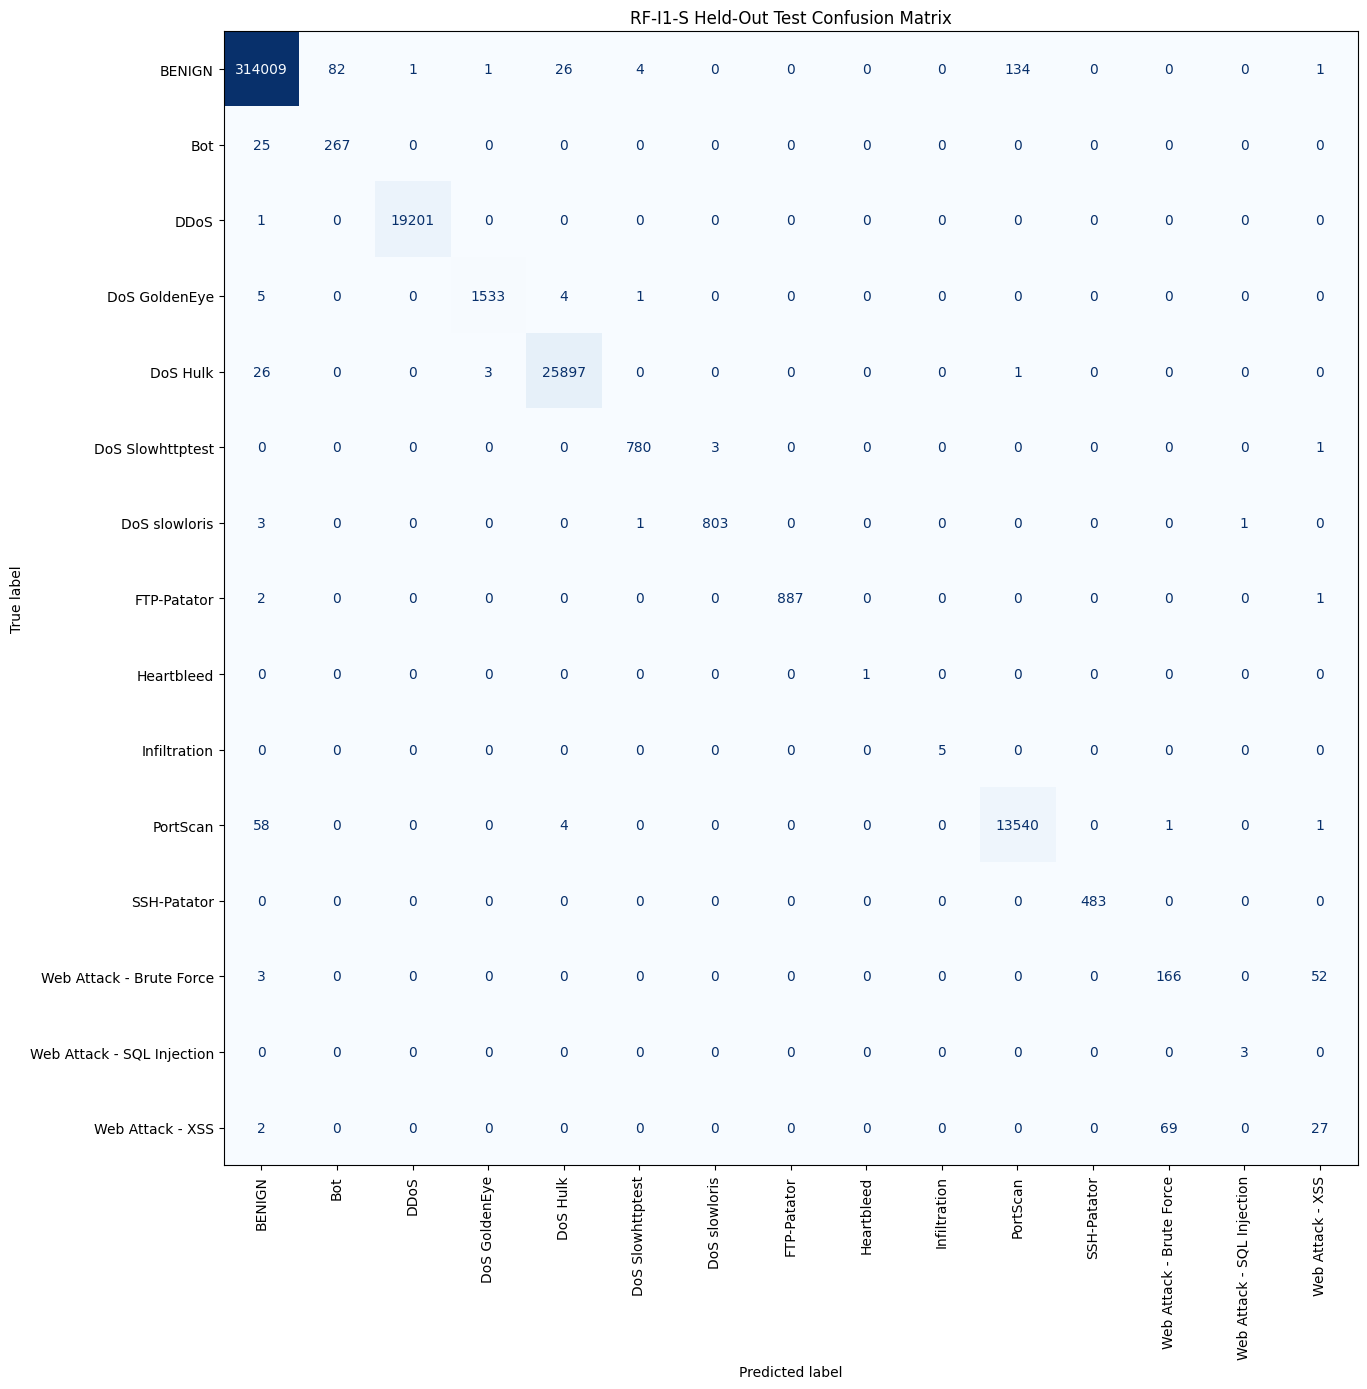

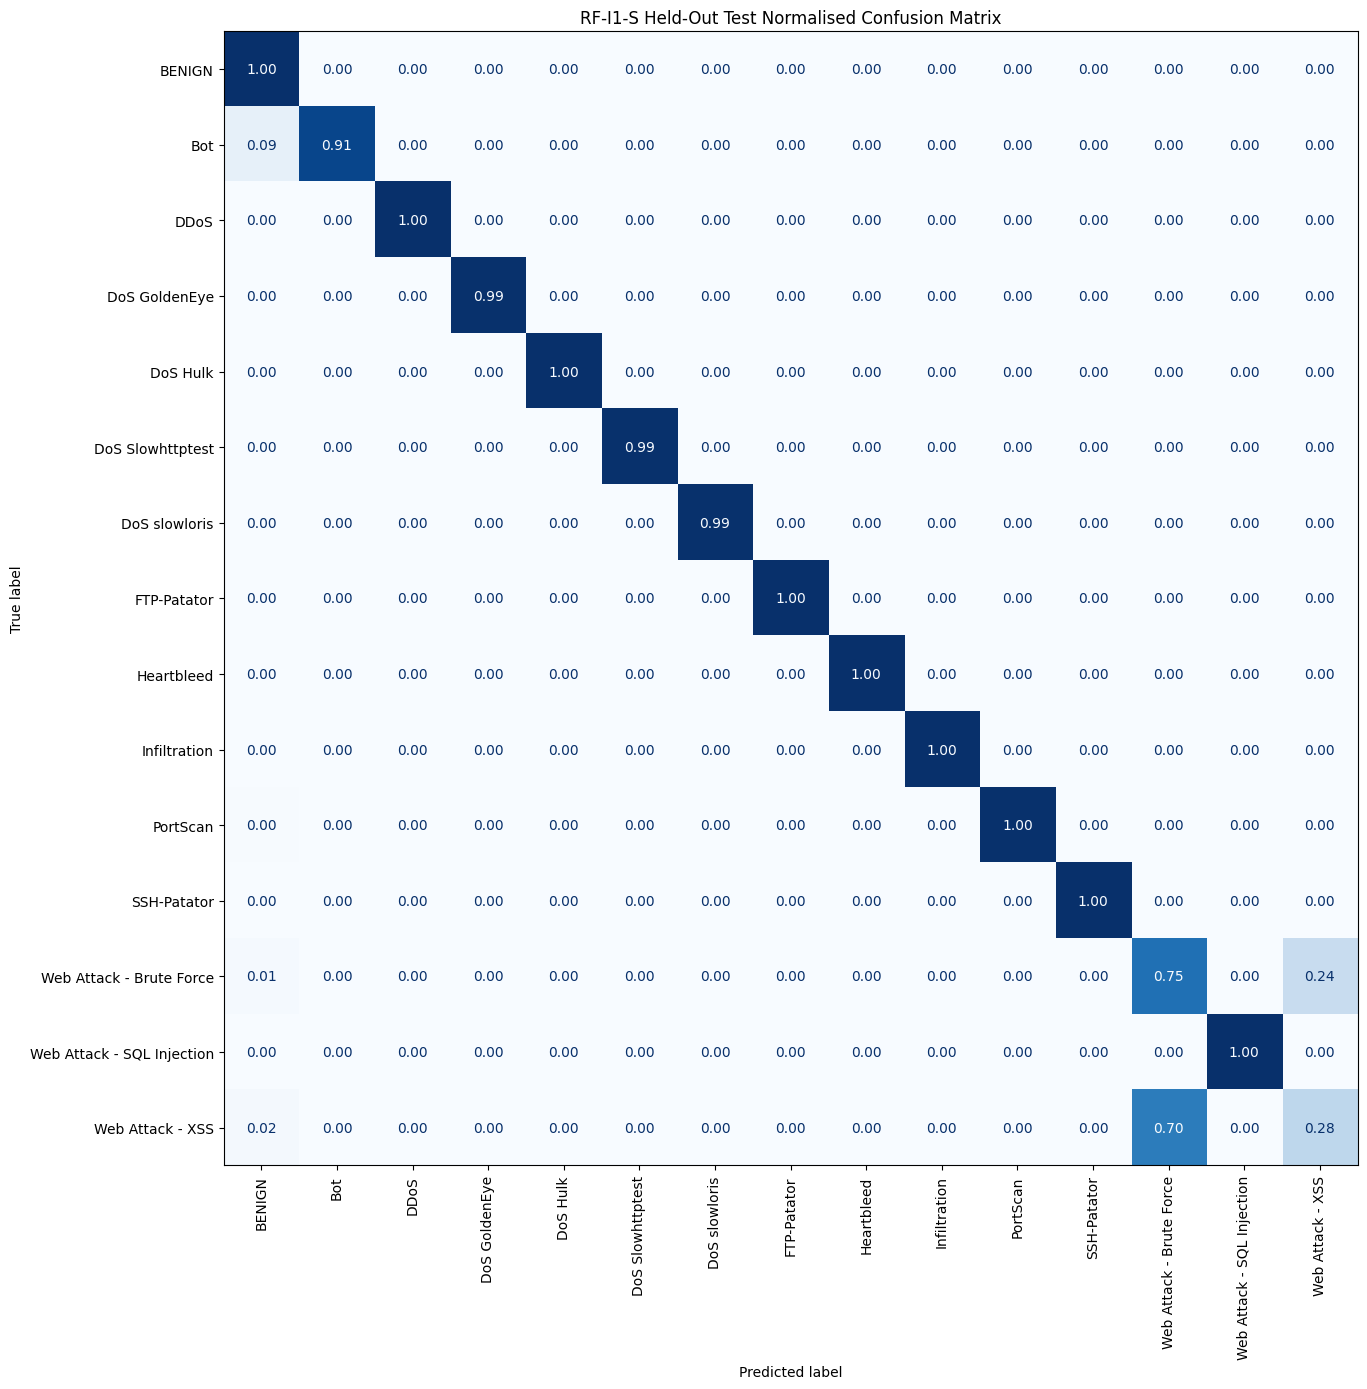


Saved artefacts:
Raw confusion matrix CSV: True
Raw confusion matrix PNG: True
Normalised confusion matrix CSV: True
Normalised confusion matrix PNG: True


In [32]:
# Cell 29 — RF-I1-S held-out test confusion matrices

print(
    "Generating RF-I1-S confusion matrices..."
)

# --------------------------------------------------
# 1. Raw confusion matrix
# --------------------------------------------------

rf_i1_s_confusion_matrix = confusion_matrix(
    rf_i1_s_test_true,
    rf_i1_s_test_pred,
    labels=CLASS_NAMES
)

assert (
    rf_i1_s_confusion_matrix.shape
    == (
        len(CLASS_NAMES),
        len(CLASS_NAMES)
    )
)

print(
    "\nConfusion matrix shape:",
    rf_i1_s_confusion_matrix.shape
)

print(
    "Total observations represented:",
    int(
        rf_i1_s_confusion_matrix.sum()
    )
)

# --------------------------------------------------
# 2. Save raw confusion matrix CSV
# --------------------------------------------------

rf_i1_s_confusion_df = pd.DataFrame(
    rf_i1_s_confusion_matrix,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

RF_I1_S_CONFUSION_CSV_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_confusion_matrix.csv"
)

rf_i1_s_confusion_df.to_csv(
    RF_I1_S_CONFUSION_CSV_PATH
)

# --------------------------------------------------
# 3. Raw-count confusion matrix
# --------------------------------------------------

RF_I1_S_CONFUSION_PNG_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_confusion_matrix.png"
)

fig, ax = plt.subplots(
    figsize=(16, 14)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=
        rf_i1_s_confusion_matrix,

    display_labels=
        CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=90,
    colorbar=False
)

ax.set_title(
    "RF-I1-S Held-Out Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    RF_I1_S_CONFUSION_PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 4. Row-normalised confusion matrix
# --------------------------------------------------

rf_i1_s_confusion_normalized = confusion_matrix(
    rf_i1_s_test_true,
    rf_i1_s_test_pred,
    labels=CLASS_NAMES,
    normalize="true"
)

RF_I1_S_CONFUSION_NORMALIZED_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_confusion_matrix_normalized.png"
)

fig, ax = plt.subplots(
    figsize=(16, 14)
)

disp_norm = ConfusionMatrixDisplay(
    confusion_matrix=
        rf_i1_s_confusion_normalized,

    display_labels=
        CLASS_NAMES
)

disp_norm.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=90,
    colorbar=False
)

ax.set_title(
    "RF-I1-S Held-Out Test "
    "Normalised Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    RF_I1_S_CONFUSION_NORMALIZED_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 5. Save normalised matrix as CSV too
# --------------------------------------------------

rf_i1_s_confusion_normalized_df = pd.DataFrame(
    rf_i1_s_confusion_normalized,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

RF_I1_S_CONFUSION_NORMALIZED_CSV_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_confusion_matrix_normalized.csv"
)

rf_i1_s_confusion_normalized_df.to_csv(
    RF_I1_S_CONFUSION_NORMALIZED_CSV_PATH
)

# --------------------------------------------------
# 6. Artefact checks
# --------------------------------------------------

print(
    "\nSaved artefacts:"
)

print(
    "Raw confusion matrix CSV:",
    os.path.exists(
        RF_I1_S_CONFUSION_CSV_PATH
    )
)

print(
    "Raw confusion matrix PNG:",
    os.path.exists(
        RF_I1_S_CONFUSION_PNG_PATH
    )
)

print(
    "Normalised confusion matrix CSV:",
    os.path.exists(
        RF_I1_S_CONFUSION_NORMALIZED_CSV_PATH
    )
)

print(
    "Normalised confusion matrix PNG:",
    os.path.exists(
        RF_I1_S_CONFUSION_NORMALIZED_PATH
    )
)

In [33]:
# Cell 30 — Save final RF-I1-S held-out test metrics

print(
    "Saving final RF-I1-S test metrics..."
)

# --------------------------------------------------
# 1. Final selected-model metrics
# --------------------------------------------------

rf_i1_s_final_metrics_df = pd.DataFrame({
    "Model": [
        "RF-I1-S"
    ],

    "Dataset": [
        "CIC-IDS2017"
    ],

    "Method": [
        "Controlled SMOTE"
    ],

    "Evaluation Split": [
        "Held-Out Test"
    ],

    "Input Features": [
        78
    ],

    "Original Training Observations": [
        len(
            train_df
        )
    ],

    "SMOTE Training Observations": [
        1815663
    ],

    "Synthetic Observations": [
        51109
    ],

    "Trees": [
        BEST_TUNED_TREES
    ],

    "Max Depth": [
        BEST_TUNED_MAX_DEPTH
    ],

    "Min Examples": [
        BEST_TUNED_MIN_EXAMPLES
    ],

    "Random Seed": [
        BEST_TUNED_RANDOM_SEED
    ],

    "Accuracy": [
        RF_I1_S_TEST_ACCURACY
    ],

    "Macro Precision": [
        RF_I1_S_TEST_MACRO_PRECISION
    ],

    "Macro Recall": [
        RF_I1_S_TEST_MACRO_RECALL
    ],

    "Macro F1": [
        RF_I1_S_TEST_MACRO_F1
    ],

    "Weighted F1": [
        RF_I1_S_TEST_WEIGHTED_F1
    ],

    "Balanced Accuracy": [
        RF_I1_S_TEST_BALANCED_ACCURACY
    ],

    "MCC": [
        RF_I1_S_TEST_MCC
    ],

    "Validation Macro F1": [
        RF_I1_S_VAL_MACRO_F1
    ],

    "Training Time Seconds": [
        RF_I1_S_TRAIN_TIME
    ],

    "SMOTE Time Seconds": [
        SMOTE_RESAMPLING_TIME
    ],

    "Prediction Time Seconds": [
        RF_I1_S_TEST_PREDICTION_TIME
    ],

    "OOB Accuracy": [
        rf_i1_s_oob.accuracy
    ],

    "OOB Log Loss": [
        rf_i1_s_oob.loss
    ],

    "Selected By Validation": [
        True
    ],

    "Selection Locked Before Test": [
        True
    ],

    "Feature Refinement Included": [
        False
    ]
})

print(
    "\nRF-I1-S FINAL TEST RESULT"
)

display(
    rf_i1_s_final_metrics_df
)

# --------------------------------------------------
# 2. Save final metrics
# --------------------------------------------------

RF_I1_S_FINAL_METRICS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_metrics.csv"
)

rf_i1_s_final_metrics_df.to_csv(
    RF_I1_S_FINAL_METRICS_PATH,
    index=False
)

# --------------------------------------------------
# 3. Compact experiment summary
# --------------------------------------------------

rf_i1_s_experiment_summary_df = pd.DataFrame({
    "Measure": [
        "Reference Model",
        "Selected Model",
        "Selected Method",
        "Original Training Observations",
        "Synthetic Observations",
        "Final Training Observations",
        "Input Features",
        "Validation Macro F1",
        "Validation Improvement vs RF-H2",
        "Test Accuracy",
        "Test Macro Precision",
        "Test Macro Recall",
        "Test Macro F1",
        "Test Weighted F1",
        "Test Balanced Accuracy",
        "Test MCC",
        "Training Time Seconds",
        "SMOTE Time Seconds",
        "Prediction Time Seconds",
        "OOB Accuracy",
        "OOB Log Loss",
        "Feature Refinement Included",
        "Selection Locked Before Test"
    ],

    "Value": [
        "RF-H2-CIC",
        "RF-I1-S",
        "Controlled SMOTE",
        len(
            train_df
        ),
        51109,
        1815663,
        78,
        RF_I1_S_VAL_MACRO_F1,
        BEST_IMBALANCE_DELTA,
        RF_I1_S_TEST_ACCURACY,
        RF_I1_S_TEST_MACRO_PRECISION,
        RF_I1_S_TEST_MACRO_RECALL,
        RF_I1_S_TEST_MACRO_F1,
        RF_I1_S_TEST_WEIGHTED_F1,
        RF_I1_S_TEST_BALANCED_ACCURACY,
        RF_I1_S_TEST_MCC,
        RF_I1_S_TRAIN_TIME,
        SMOTE_RESAMPLING_TIME,
        RF_I1_S_TEST_PREDICTION_TIME,
        rf_i1_s_oob.accuracy,
        rf_i1_s_oob.loss,
        False,
        True
    ]
})

RF_I1_S_EXPERIMENT_SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_experiment_summary.csv"
)

rf_i1_s_experiment_summary_df.to_csv(
    RF_I1_S_EXPERIMENT_SUMMARY_PATH,
    index=False
)

# --------------------------------------------------
# 4. Display compact final summary
# --------------------------------------------------

print(
    "\nRF-I1-S SUMMARY"
)

print(
    "Validation Macro F1:",
    round(
        RF_I1_S_VAL_MACRO_F1,
        6
    )
)

print(
    "Test Macro F1:",
    round(
        RF_I1_S_TEST_MACRO_F1,
        6
    )
)

print(
    "Test Macro Recall:",
    round(
        RF_I1_S_TEST_MACRO_RECALL,
        6
    )
)

print(
    "Test Balanced Accuracy:",
    round(
        RF_I1_S_TEST_BALANCED_ACCURACY,
        6
    )
)

print(
    "Test MCC:",
    round(
        RF_I1_S_TEST_MCC,
        6
    )
)

print(
    "Training time:",
    round(
        RF_I1_S_TRAIN_TIME,
        3
    ),
    "seconds"
)

print(
    "Synthetic observations:",
    51109
)

print(
    "\nSelected by validation:",
    True
)

print(
    "Feature refinement included:",
    False
)

# --------------------------------------------------
# 5. Artefact verification
# --------------------------------------------------

print(
    "\nSaved artefacts:"
)

print(
    "Final metrics CSV:",
    os.path.exists(
        RF_I1_S_FINAL_METRICS_PATH
    )
)

print(
    "Experiment summary CSV:",
    os.path.exists(
        RF_I1_S_EXPERIMENT_SUMMARY_PATH
    )
)

print(
    "Classification report:",
    os.path.exists(
        RF_I1_S_CLASS_REPORT_PATH
    )
)

print(
    "Per-class metrics:",
    os.path.exists(
        RF_I1_S_PER_CLASS_PATH
    )
)

print(
    "Confusion matrix:",
    os.path.exists(
        RF_I1_S_CONFUSION_PNG_PATH
    )
)

print(
    "Normalised confusion matrix:",
    os.path.exists(
        RF_I1_S_CONFUSION_NORMALIZED_PATH
    )
)

print(
    "\nRF-I1-S final metrics saved."
)

Saving final RF-I1-S test metrics...

RF-I1-S FINAL TEST RESULT


,Model,Dataset,Method,Evaluation Split,Input Features,Original Training Observations,SMOTE Training Observations,Synthetic Observations,Trees,Max Depth,...,MCC,Validation Macro F1,Training Time Seconds,SMOTE Time Seconds,Prediction Time Seconds,OOB Accuracy,OOB Log Loss,Selected By Validation,Selection Locked Before Test,Feature Refinement Included
0,RF-I1-S,CIC-IDS2017,Controlled SMOTE,Held-Out Test,78,1764554,1815663,51109,100,30,...,0.995457,0.887868,297.767555,5.701057,14.252611,0.998375,0.017245,True,True,False



RF-I1-S SUMMARY
Validation Macro F1: 0.887868
Test Macro F1: 0.912553
Test Macro Recall: 0.927545
Test Balanced Accuracy: 0.927545
Test MCC: 0.995457
Training time: 297.768 seconds
Synthetic observations: 51109

Selected by validation: True
Feature refinement included: False

Saved artefacts:
Final metrics CSV: True
Experiment summary CSV: True
Classification report: True
Per-class metrics: True
Confusion matrix: True
Normalised confusion matrix: True

RF-I1-S final metrics saved.


In [34]:
# Cell 31 — Final RF-H2-CIC vs RF-I1-S comparison
#
# IMPORTANT:
# RF-I1-S was selected using validation performance
# before its held-out test set was evaluated.
#
# The RF-H2 values below are frozen results from the
# completed RF-H2-CIC experiment.

print(
    "Comparing RF-H2-CIC with selected RF-I1-S..."
)

# --------------------------------------------------
# 1. Frozen RF-H2-CIC held-out test results
# --------------------------------------------------

RF_H2_TEST_ACCURACY = 0.998707
RF_H2_TEST_MACRO_PRECISION = 0.932351
RF_H2_TEST_MACRO_RECALL = 0.874790
RF_H2_TEST_MACRO_F1 = 0.888474
RF_H2_TEST_WEIGHTED_F1 = 0.998655
RF_H2_TEST_BALANCED_ACCURACY = 0.874790
RF_H2_TEST_MCC = 0.995699
RF_H2_TRAIN_TIME = 315.334803

# --------------------------------------------------
# 2. Calculate RF-I1-S changes relative to RF-H2
# --------------------------------------------------

DELTA_TEST_ACCURACY = (
    RF_I1_S_TEST_ACCURACY
    - RF_H2_TEST_ACCURACY
)

DELTA_TEST_MACRO_PRECISION = (
    RF_I1_S_TEST_MACRO_PRECISION
    - RF_H2_TEST_MACRO_PRECISION
)

DELTA_TEST_MACRO_RECALL = (
    RF_I1_S_TEST_MACRO_RECALL
    - RF_H2_TEST_MACRO_RECALL
)

DELTA_TEST_MACRO_F1 = (
    RF_I1_S_TEST_MACRO_F1
    - RF_H2_TEST_MACRO_F1
)

DELTA_TEST_WEIGHTED_F1 = (
    RF_I1_S_TEST_WEIGHTED_F1
    - RF_H2_TEST_WEIGHTED_F1
)

DELTA_TEST_BALANCED_ACCURACY = (
    RF_I1_S_TEST_BALANCED_ACCURACY
    - RF_H2_TEST_BALANCED_ACCURACY
)

DELTA_TEST_MCC = (
    RF_I1_S_TEST_MCC
    - RF_H2_TEST_MCC
)

DELTA_TRAIN_TIME = (
    RF_I1_S_TRAIN_TIME
    - RF_H2_TRAIN_TIME
)

RELATIVE_MACRO_F1_CHANGE = (
    DELTA_TEST_MACRO_F1
    / RF_H2_TEST_MACRO_F1
) * 100

RELATIVE_MACRO_RECALL_CHANGE = (
    DELTA_TEST_MACRO_RECALL
    / RF_H2_TEST_MACRO_RECALL
) * 100

RELATIVE_TRAIN_TIME_CHANGE = (
    DELTA_TRAIN_TIME
    / RF_H2_TRAIN_TIME
) * 100

# --------------------------------------------------
# 3. Main comparison table
# --------------------------------------------------

rf_h2_vs_i1_s_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Balanced Accuracy",
        "MCC",
        "Training Time Seconds"
    ],

    "RF-H2-CIC": [
        RF_H2_TEST_ACCURACY,
        RF_H2_TEST_MACRO_PRECISION,
        RF_H2_TEST_MACRO_RECALL,
        RF_H2_TEST_MACRO_F1,
        RF_H2_TEST_WEIGHTED_F1,
        RF_H2_TEST_BALANCED_ACCURACY,
        RF_H2_TEST_MCC,
        RF_H2_TRAIN_TIME
    ],

    "RF-I1-S": [
        RF_I1_S_TEST_ACCURACY,
        RF_I1_S_TEST_MACRO_PRECISION,
        RF_I1_S_TEST_MACRO_RECALL,
        RF_I1_S_TEST_MACRO_F1,
        RF_I1_S_TEST_WEIGHTED_F1,
        RF_I1_S_TEST_BALANCED_ACCURACY,
        RF_I1_S_TEST_MCC,
        RF_I1_S_TRAIN_TIME
    ],

    "Absolute Change": [
        DELTA_TEST_ACCURACY,
        DELTA_TEST_MACRO_PRECISION,
        DELTA_TEST_MACRO_RECALL,
        DELTA_TEST_MACRO_F1,
        DELTA_TEST_WEIGHTED_F1,
        DELTA_TEST_BALANCED_ACCURACY,
        DELTA_TEST_MCC,
        DELTA_TRAIN_TIME
    ]
})

print(
    "\nRF-H2-CIC VS RF-I1-S — HELD-OUT TEST"
)

display(
    rf_h2_vs_i1_s_df
)

# --------------------------------------------------
# 4. Validation-selection evidence
# --------------------------------------------------

rf_h2_vs_i1_s_validation_df = pd.DataFrame({
    "Model": [
        "RF-H2-CIC",
        "RF-I1-S"
    ],

    "Method": [
        "Tuned RF",
        "Tuned RF + Controlled SMOTE"
    ],

    "Validation Macro F1": [
        RF_H2_VAL_MACRO_F1,
        RF_I1_S_VAL_MACRO_F1
    ],

    "Selected": [
        False,
        True
    ]
})

print(
    "\nVALIDATION-SELECTION EVIDENCE"
)

display(
    rf_h2_vs_i1_s_validation_df
)

# --------------------------------------------------
# 5. Key quantitative changes
# --------------------------------------------------

print(
    "\nKEY TEST-SET CHANGES"
)

print(
    "Accuracy change:",
    f"{DELTA_TEST_ACCURACY:+.6f}"
)

print(
    "Macro Precision change:",
    f"{DELTA_TEST_MACRO_PRECISION:+.6f}"
)

print(
    "Macro Recall change:",
    f"{DELTA_TEST_MACRO_RECALL:+.6f}"
)

print(
    "Macro F1 change:",
    f"{DELTA_TEST_MACRO_F1:+.6f}"
)

print(
    "Weighted F1 change:",
    f"{DELTA_TEST_WEIGHTED_F1:+.6f}"
)

print(
    "Balanced Accuracy change:",
    f"{DELTA_TEST_BALANCED_ACCURACY:+.6f}"
)

print(
    "MCC change:",
    f"{DELTA_TEST_MCC:+.6f}"
)

print(
    "Training time change:",
    f"{DELTA_TRAIN_TIME:+.3f}",
    "seconds"
)

print(
    "\nRelative Macro F1 change:",
    f"{RELATIVE_MACRO_F1_CHANGE:+.2f}%"
)

print(
    "Relative Macro Recall change:",
    f"{RELATIVE_MACRO_RECALL_CHANGE:+.2f}%"
)

print(
    "Relative training-time change:",
    f"{RELATIVE_TRAIN_TIME_CHANGE:+.2f}%"
)

# --------------------------------------------------
# 6. Interpretation record
# --------------------------------------------------

RF_I1_S_FINAL_INTERPRETATION = (
    "Relative to the frozen RF-H2-CIC reference, "
    "RF-I1-S increased held-out test Macro F1 and "
    "Macro Recall while producing small reductions "
    "in overall Accuracy, Macro Precision, Weighted "
    "F1 and MCC. The result indicates that controlled "
    "SMOTE improved class-balanced intrusion detection "
    "performance, particularly sensitivity to minority "
    "classes, at the cost of a modest increase in "
    "false-positive behaviour. Model selection was "
    "performed using validation Macro F1 before the "
    "held-out test set was accessed."
)

print(
    "\nINTERPRETATION"
)

print(
    RF_I1_S_FINAL_INTERPRETATION
)

# --------------------------------------------------
# 7. Save comparison artefacts
# --------------------------------------------------

RF_H2_VS_I1_S_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_vs_RF_I1_S_test_comparison.csv"
)

RF_H2_VS_I1_S_VALIDATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_vs_RF_I1_S_validation_comparison.csv"
)

rf_h2_vs_i1_s_df.to_csv(
    RF_H2_VS_I1_S_PATH,
    index=False
)

rf_h2_vs_i1_s_validation_df.to_csv(
    RF_H2_VS_I1_S_VALIDATION_PATH,
    index=False
)

# --------------------------------------------------
# 8. Save human-readable interpretation
# --------------------------------------------------

RF_I1_S_INTERPRETATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_S_final_interpretation.txt"
)

with open(
    RF_I1_S_INTERPRETATION_PATH,
    "w"
) as interpretation_file:

    interpretation_file.write(
        "RF-H2-CIC VS RF-I1-S\n"
        "FINAL COMPARISON\n\n"
    )

    interpretation_file.write(
        f"RF-H2 validation Macro F1: "
        f"{RF_H2_VAL_MACRO_F1:.6f}\n"
    )

    interpretation_file.write(
        f"RF-I1-S validation Macro F1: "
        f"{RF_I1_S_VAL_MACRO_F1:.6f}\n"
    )

    interpretation_file.write(
        f"Validation improvement: "
        f"{BEST_IMBALANCE_DELTA:+.6f}\n\n"
    )

    interpretation_file.write(
        f"RF-H2 test Macro F1: "
        f"{RF_H2_TEST_MACRO_F1:.6f}\n"
    )

    interpretation_file.write(
        f"RF-I1-S test Macro F1: "
        f"{RF_I1_S_TEST_MACRO_F1:.6f}\n"
    )

    interpretation_file.write(
        f"Test Macro F1 change: "
        f"{DELTA_TEST_MACRO_F1:+.6f}\n"
    )

    interpretation_file.write(
        f"Test Macro Recall change: "
        f"{DELTA_TEST_MACRO_RECALL:+.6f}\n"
    )

    interpretation_file.write(
        f"Test Macro Precision change: "
        f"{DELTA_TEST_MACRO_PRECISION:+.6f}\n\n"
    )

    interpretation_file.write(
        RF_I1_S_FINAL_INTERPRETATION
    )

# --------------------------------------------------
# 9. Artefact verification
# --------------------------------------------------

print(
    "\nSaved artefacts:"
)

print(
    "Test comparison:",
    os.path.exists(
        RF_H2_VS_I1_S_PATH
    )
)

print(
    "Validation comparison:",
    os.path.exists(
        RF_H2_VS_I1_S_VALIDATION_PATH
    )
)

print(
    "Interpretation record:",
    os.path.exists(
        RF_I1_S_INTERPRETATION_PATH
    )
)

Comparing RF-H2-CIC with selected RF-I1-S...

RF-H2-CIC VS RF-I1-S — HELD-OUT TEST


,Metric,RF-H2-CIC,RF-I1-S,Absolute Change
0,Accuracy,0.998707,0.998633,-0.000074
1,Macro Precision,0.932351,0.901210,-0.031141
2,Macro Recall,0.874790,0.927545,0.052755
3,Macro F1,0.888474,0.912553,0.024079
4,Weighted F1,0.998655,0.998638,-0.000017
5,Balanced Accuracy,0.874790,0.927545,0.052755
6,MCC,0.995699,0.995457,-0.000242
7,Training Time Seconds,315.334803,297.767555,-17.567248



VALIDATION-SELECTION EVIDENCE


,Model,Method,Validation Macro F1,Selected
0,RF-H2-CIC,Tuned RF,0.881331,False
1,RF-I1-S,Tuned RF + Controlled SMOTE,0.887868,True



KEY TEST-SET CHANGES
Accuracy change: -0.000074
Macro Precision change: -0.031141
Macro Recall change: +0.052755
Macro F1 change: +0.024079
Weighted F1 change: -0.000017
Balanced Accuracy change: +0.052755
MCC change: -0.000242
Training time change: -17.567 seconds

Relative Macro F1 change: +2.71%
Relative Macro Recall change: +6.03%
Relative training-time change: -5.57%

INTERPRETATION
Relative to the frozen RF-H2-CIC reference, RF-I1-S increased held-out test Macro F1 and Macro Recall while producing small reductions in overall Accuracy, Macro Precision, Weighted F1 and MCC. The result indicates that controlled SMOTE improved class-balanced intrusion detection performance, particularly sensitivity to minority classes, at the cost of a modest increase in false-positive behaviour. Model selection was performed using validation Macro F1 before the held-out test set was accessed.

Saved artefacts:
Test comparison: True
Validation comparison: True
Interpretation record: True


In [35]:
# Cell 32 — Final integrity checks and freeze RF-I1-CIC

print(
    "Running final RF-I1-CIC integrity checks..."
)

# --------------------------------------------------
# 1. Verify locked experimental decisions
# --------------------------------------------------

assert (
    SELECTED_IMBALANCE_MODEL
    == "RF-I1-S"
)

assert (
    SELECTED_IMBALANCE_METHOD
    == "Controlled SMOTE"
)

assert (
    IMBALANCE_SELECTED
    is True
)

assert (
    feature_selected
    is False
)

assert (
    RF_I1_S_VAL_MACRO_F1
    > RF_H2_VAL_MACRO_F1
)

assert (
    BEST_IMBALANCE_VAL_MACRO_F1
    == RF_I1_S_VAL_MACRO_F1
)

print(
    "\nDecision integrity: PASSED"
)

# --------------------------------------------------
# 2. Verify final numerical results
# --------------------------------------------------

assert np.isfinite(
    RF_I1_S_TEST_ACCURACY
)

assert np.isfinite(
    RF_I1_S_TEST_MACRO_PRECISION
)

assert np.isfinite(
    RF_I1_S_TEST_MACRO_RECALL
)

assert np.isfinite(
    RF_I1_S_TEST_MACRO_F1
)

assert np.isfinite(
    RF_I1_S_TEST_WEIGHTED_F1
)

assert np.isfinite(
    RF_I1_S_TEST_BALANCED_ACCURACY
)

assert np.isfinite(
    RF_I1_S_TEST_MCC
)

assert (
    len(
        rf_i1_s_test_true
    )
    == 378119
)

assert (
    len(
        rf_i1_s_test_pred
    )
    == 378119
)

assert (
    len(
        np.unique(
            rf_i1_s_test_pred
        )
    )
    == 15
)

print(
    "Test-result integrity: PASSED"
)

# --------------------------------------------------
# 3. Verify confusion matrix integrity
# --------------------------------------------------

assert (
    rf_i1_s_confusion_matrix.shape
    == (15, 15)
)

assert (
    int(
        rf_i1_s_confusion_matrix.sum()
    )
    == 378119
)

print(
    "Confusion-matrix integrity: PASSED"
)

# --------------------------------------------------
# 4. Required final artefacts
# --------------------------------------------------

required_final_artefacts = {
    "RF-I1-W validation":
        RF_I1_W_VALIDATION_PATH,

    "RF-I1-S validation":
        RF_I1_S_VALIDATION_PATH,

    "RF-I1-A status":
        RF_I1_A_STATUS_PATH,

    "RF-I1-A failure note":
        RF_I1_A_FAILURE_NOTE_PATH,

    "RF-I1-B validation":
        RF_I1_B_VALIDATION_PATH,

    "Validation comparison":
        RF_I1_VALIDATION_COMPARISON_PATH,

    "Validation ranking":
        RF_I1_VALIDATION_RANKING_PATH,

    "Selection decision":
        RF_I1_DECISION_PATH,

    "Selection lock":
        RF_I1_SELECTION_LOCK_PATH,

    "Validation completion marker":
        RF_I1_VALIDATION_COMPLETE_PATH,

    "Selected RF-I1-S model":
        RF_I1_S_MODEL_DIR,

    "RF-I1-S test evaluation":
        RF_I1_S_TEST_EVALUATION_PATH,

    "RF-I1-S final metrics":
        RF_I1_S_FINAL_METRICS_PATH,

    "RF-I1-S experiment summary":
        RF_I1_S_EXPERIMENT_SUMMARY_PATH,

    "Classification report":
        RF_I1_S_CLASS_REPORT_PATH,

    "Per-class metrics":
        RF_I1_S_PER_CLASS_PATH,

    "Raw confusion matrix CSV":
        RF_I1_S_CONFUSION_CSV_PATH,

    "Raw confusion matrix PNG":
        RF_I1_S_CONFUSION_PNG_PATH,

    "Normalised confusion matrix CSV":
        RF_I1_S_CONFUSION_NORMALIZED_CSV_PATH,

    "Normalised confusion matrix PNG":
        RF_I1_S_CONFUSION_NORMALIZED_PATH,

    "RF-H2 vs RF-I1-S test comparison":
        RF_H2_VS_I1_S_PATH,

    "RF-H2 vs RF-I1-S validation comparison":
        RF_H2_VS_I1_S_VALIDATION_PATH,

    "Final interpretation":
        RF_I1_S_INTERPRETATION_PATH
}

artefact_check_rows = []

all_final_artefacts_exist = True

print(
    "\nFINAL ARTEFACT VERIFICATION"
)

for name, path in (
    required_final_artefacts.items()
):

    exists = os.path.exists(
        path
    )

    artefact_check_rows.append({
        "Artefact": name,
        "Path": path,
        "Exists": exists
    })

    print(
        f"{name}: {exists}"
    )

    if not exists:
        all_final_artefacts_exist = False

assert (
    all_final_artefacts_exist
    is True
)

# --------------------------------------------------
# 5. Save artefact integrity table
# --------------------------------------------------

rf_i1_final_artefact_check_df = pd.DataFrame(
    artefact_check_rows
)

RF_I1_FINAL_ARTEFACT_CHECK_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_final_artefact_check.csv"
)

rf_i1_final_artefact_check_df.to_csv(
    RF_I1_FINAL_ARTEFACT_CHECK_PATH,
    index=False
)

# --------------------------------------------------
# 6. Final notebook summary
# --------------------------------------------------

rf_i1_final_summary_df = pd.DataFrame({
    "Item": [
        "Notebook",
        "Dataset",
        "Reference Model",
        "Selected Imbalance Model",
        "Selected Method",
        "Primary Selection Metric",
        "RF-H2 Validation Macro F1",
        "RF-I1-S Validation Macro F1",
        "Validation Improvement",
        "Test Accuracy",
        "Test Macro Precision",
        "Test Macro Recall",
        "Test Macro F1",
        "Test Weighted F1",
        "Test Balanced Accuracy",
        "Test MCC",
        "Original Training Observations",
        "Synthetic Observations",
        "SMOTE Training Observations",
        "Input Features",
        "Feature Refinement Included",
        "ADASYN Outcome",
        "Selection Locked Before Test",
        "Final Status"
    ],

    "Value": [
        "06_RF_I1_Imbalance_CICIDS2017",
        "CIC-IDS2017",
        "RF-H2-CIC",
        "RF-I1-S",
        "Controlled SMOTE",
        "Validation Macro F1",
        RF_H2_VAL_MACRO_F1,
        RF_I1_S_VAL_MACRO_F1,
        BEST_IMBALANCE_DELTA,
        RF_I1_S_TEST_ACCURACY,
        RF_I1_S_TEST_MACRO_PRECISION,
        RF_I1_S_TEST_MACRO_RECALL,
        RF_I1_S_TEST_MACRO_F1,
        RF_I1_S_TEST_WEIGHTED_F1,
        RF_I1_S_TEST_BALANCED_ACCURACY,
        RF_I1_S_TEST_MCC,
        1764554,
        51109,
        1815663,
        78,
        False,
        "Infeasible under locked configuration",
        True,
        "COMPLETE AND FROZEN"
    ]
})

RF_I1_FINAL_SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_final_summary.csv"
)

rf_i1_final_summary_df.to_csv(
    RF_I1_FINAL_SUMMARY_PATH,
    index=False
)

print(
    "\nFINAL RF-I1-CIC SUMMARY"
)

display(
    rf_i1_final_summary_df
)

# --------------------------------------------------
# 7. Create formal freeze marker
# --------------------------------------------------

RF_I1_FREEZE_MARKER_PATH = os.path.join(
    RESULTS_DIR,
    "RF_I1_CIC_COMPLETE_AND_FROZEN.txt"
)

with open(
    RF_I1_FREEZE_MARKER_PATH,
    "w"
) as freeze_file:

    freeze_file.write(
        "RF-I1-CIC COMPLETE AND FROZEN\n\n"
    )

    freeze_file.write(
        "Dataset: CIC-IDS2017\n"
    )

    freeze_file.write(
        "Reference model: RF-H2-CIC\n"
    )

    freeze_file.write(
        "Selected imbalance model: RF-I1-S\n"
    )

    freeze_file.write(
        "Selected method: Controlled SMOTE\n\n"
    )

    freeze_file.write(
        f"RF-H2 validation Macro F1: "
        f"{RF_H2_VAL_MACRO_F1:.6f}\n"
    )

    freeze_file.write(
        f"RF-I1-S validation Macro F1: "
        f"{RF_I1_S_VAL_MACRO_F1:.6f}\n"
    )

    freeze_file.write(
        f"Validation improvement: "
        f"{BEST_IMBALANCE_DELTA:+.6f}\n\n"
    )

    freeze_file.write(
        f"RF-I1-S test Accuracy: "
        f"{RF_I1_S_TEST_ACCURACY:.6f}\n"
    )

    freeze_file.write(
        f"RF-I1-S test Macro Precision: "
        f"{RF_I1_S_TEST_MACRO_PRECISION:.6f}\n"
    )

    freeze_file.write(
        f"RF-I1-S test Macro Recall: "
        f"{RF_I1_S_TEST_MACRO_RECALL:.6f}\n"
    )

    freeze_file.write(
        f"RF-I1-S test Macro F1: "
        f"{RF_I1_S_TEST_MACRO_F1:.6f}\n"
    )

    freeze_file.write(
        f"RF-I1-S test Balanced Accuracy: "
        f"{RF_I1_S_TEST_BALANCED_ACCURACY:.6f}\n"
    )

    freeze_file.write(
        f"RF-I1-S test MCC: "
        f"{RF_I1_S_TEST_MCC:.6f}\n\n"
    )

    freeze_file.write(
        "Feature refinement included: False\n"
    )

    freeze_file.write(
        "ADASYN outcome: Infeasible under "
        "locked configuration\n"
    )

    freeze_file.write(
        "Model selection locked before "
        "held-out test: True\n\n"
    )

    freeze_file.write(
        "No further model-selection changes "
        "are permitted in this notebook.\n"
    )

# --------------------------------------------------
# 8. Final integrity flags
# --------------------------------------------------

RF_I1_COMPLETE = True
RF_I1_FROZEN = True

print(
    "\nFinal integrity artefact:",
    os.path.exists(
        RF_I1_FINAL_ARTEFACT_CHECK_PATH
    )
)

print(
    "Final summary:",
    os.path.exists(
        RF_I1_FINAL_SUMMARY_PATH
    )
)

print(
    "Freeze marker:",
    os.path.exists(
        RF_I1_FREEZE_MARKER_PATH
    )
)

print(
    "All required artefacts:",
    all_final_artefacts_exist
)

print(
    "\nRF-I1_COMPLETE:",
    RF_I1_COMPLETE
)

print(
    "RF-I1_FROZEN:",
    RF_I1_FROZEN
)

print(
    "\nFINAL INTEGRITY CHECK: PASSED"
)

print(
    "RF-I1-CIC COMPLETE AND FROZEN."
)

Running final RF-I1-CIC integrity checks...

Decision integrity: PASSED
Test-result integrity: PASSED
Confusion-matrix integrity: PASSED

FINAL ARTEFACT VERIFICATION
RF-I1-W validation: True
RF-I1-S validation: True
RF-I1-A status: True
RF-I1-A failure note: True
RF-I1-B validation: True
Validation comparison: True
Validation ranking: True
Selection decision: True
Selection lock: True
Validation completion marker: True
Selected RF-I1-S model: True
RF-I1-S test evaluation: True
RF-I1-S final metrics: True
RF-I1-S experiment summary: True
Classification report: True
Per-class metrics: True
Raw confusion matrix CSV: True
Raw confusion matrix PNG: True
Normalised confusion matrix CSV: True
Normalised confusion matrix PNG: True
RF-H2 vs RF-I1-S test comparison: True
RF-H2 vs RF-I1-S validation comparison: True
Final interpretation: True

FINAL RF-I1-CIC SUMMARY


,Item,Value
0,Notebook,06_RF_I1_Imbalance_CICIDS2017
1,Dataset,CIC-IDS2017
2,Reference Model,RF-H2-CIC
3,Selected Imbalance Model,RF-I1-S
4,Selected Method,Controlled SMOTE
5,Primary Selection Metric,Validation Macro F1
6,RF-H2 Validation Macro F1,0.881331
7,RF-I1-S Validation Macro F1,0.887868
8,Validation Improvement,0.006537
9,Test Accuracy,0.998633



Final integrity artefact: True
Final summary: True
Freeze marker: True
All required artefacts: True

RF-I1_COMPLETE: True
RF-I1_FROZEN: True

FINAL INTEGRITY CHECK: PASSED
RF-I1-CIC COMPLETE AND FROZEN.
